In [1]:
# Settings
from pathlib import Path
import json, os, string, warnings, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap, to_rgba
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from matplotlib.patches import Patch, PathPatch
from matplotlib.path import Path as MplPath
from matplotlib.transforms import blended_transform_factory
from scipy.stats import chi2
from scipy.spatial import ConvexHull
from scipy.ndimage import binary_dilation, binary_closing, gaussian_filter
from IPython.display import display

DATA_FOLDER = Path('Data')
FIGURE_FOLDER = DATA_FOLDER / 'figures' / 'Metasomatism'
FIGURE_FOLDER.mkdir(parents=True, exist_ok=True)
CONSTANTS_FILE = DATA_FOLDER / 'melting_constants.xlsx'
RESIDUE_FILE = DATA_FOLDER / 'metasomatism_starting_states_runs.csv'
MELT_FILE = r'C:\Users\anast\MAGEMin_melting\hydrous_melting_path_3GPa_lowF.csv'

NVP_FILE = Path.home() / 'Anastasia_Morfiadakis_MESA' / 'Data' / 'Summary Data SE Aus xenoliths.xlsx'
NVP_CPX_FILE = DATA_FOLDER / 'NVP_cpx_LA_noRZ.csv'
JULIA_EXE = r'C:\Users\anast\.julia\juliaup\julia-1.12.7+0.x64.w64.mingw32\bin\julia.exe'
JULIA_PROJECT = r'C:\Users\anast\.julia\environments\v1.12'


RESIDUE = dict(P_GPa=1.5, style='continuous', D_mode='variable', F=0.1)
HYDROUS = {'very low': 0.16, 'low': 0.6, 'mid': 1.6, 'high': 2.6}
X_VALUES = [
    0.0005, 0.001, 0.0015, 0.002, 0.003, 0.004, 0.005,
    0.0075, 0.01, 0.0125, 0.015, 0.02, 0.025, 0.03,
    0.04, 0.05, 0.075, 0.10, 0.125, 0.15, 0.175, 0.20
]
T_RECRYST = 900.0
PHI = 0.01
AMP_FACTOR = 1.6
CPX_TOL = 1e-4

SPL_RESIDUES = dict(P_GPa=1.5, style='continuous', D_mode='variable')
D_CUT = np.sqrt(chi2.ppf(0.95, 4))
D_BROAD = 6.0
X_REAL = 0.1
SITES = ['Mt Shadwell', 'Mt Leura', 'Mt Gambier']
SAMPLES = ['MSHAD_AA_1', 'MSHAD_AA_2', 'MSHAD_AA_3', 'MSHAD_AA_4', 'MSHAD_AA_5', '70984', '70994', '71002', '71008a', '71008b', '76996', '76997', '76998', '76999',
           'MG_SA_1', 'MG_SA_2', 'MG_SA_3', 'MG_SA_5', 'MG_SA_6', 'MG_SA_7']

PATTERN = {**dict.fromkeys(['MG_SA_1', 'MG_SA_2', 'MG_SA_5', 'MG_SA_6', 'MG_SA_7'], 'Gambier-type'),
           **dict.fromkeys(['MSHAD_AA_1', 'MSHAD_AA_3', 'MSHAD_AA_4', 'MSHAD_AA_5'], 'Flat HREE'),
           **dict.fromkeys(['MG_SA_3', 'MSHAD_AA_2'], 'Low HREE')}

def pattern_of(d):
    return d['xenolith'].astype(str).str.upper().map(PATTERN).fillna('Humped')

OXIDES = ['SiO2', 'Al2O3', 'CaO', 'MgO', 'FeO', 'K2O', 'Na2O', 'TiO2', 'O', 'Cr2O3', 'H2O']

In [2]:
# Constants, depleted residues and metasomatic agents
const = pd.read_excel(CONSTANTS_FILE, sheet_name=None)
ree_df = const['REE'].iloc[:, :5]
REE = ree_df['Element'].astype(str).tolist()
RADII = ree_df['Ionic radius '].to_numpy(float)
CI_ARR = ree_df['CI chondrite (ppm)'].to_numpy(float)
SOURCE_PM = const['Sources_REE'].set_index('Element').loc[REE, 'PM_PO14 (ppm)'].to_numpy(float)

pc = const['Partition_Coef'].set_index('REE')
D = {ph: pc.loc[REE, ph].to_numpy(float) for ph in ('Olivine', 'Orthopyroxene', 'Clinopyroxene', 'Spinel', 'Garnet')}
D['Amphibole'], D['Phlogopite'] = AMP_FACTOR * D['Clinopyroxene'], np.zeros(len(REE))
Dcpx = D['Clinopyroxene']

def bulk_D(modes):
    return sum(m * D[ph] for ph, m in modes.items() if ph in D)

RES_MODE_COLS = {'Olivine': 'ol_solid', 'Orthopyroxene': 'opx_solid', 'Clinopyroxene': 'cpx_solid', 'Spinel': 'spl_solid',
                 'Garnet': 'g_solid'}
res_all = pd.read_csv(RESIDUE_FILE)

def select(spec):
    keep = np.ones(len(res_all), bool)
    for key, val in spec.items():
        col = res_all[key]
        keep &= np.isclose(col.astype(float), val) if isinstance(val, (int, float)) else col.astype(str).eq(str(val)).to_numpy()
    return res_all[keep].sort_values('F').reset_index(drop=True)

def residue(row, modes=None, P_GPa=None, label=''):
    modes = modes or {ph: float(row[c]) for ph, c in RES_MODE_COLS.items()}
    modes = {ph: m / sum(modes.values()) for ph, m in modes.items()}
    C = row[[f'{el}_residue' for el in REE]].to_numpy(float)
    wt = np.array([float(row.get(ox, 0.0)) for ox in OXIDES])
    return dict(C=C, wt=100 * wt / wt.sum(), modes=modes, cpx=C * Dcpx / bulk_D(modes), F=float(row['F']),
                P_GPa=float(row['P_GPa'] if P_GPa is None else P_GPa), set=label)

res6 = residue(select(RESIDUE).iloc[0])

path_full = pd.read_csv(MELT_FILE).sort_values('H2O_mol').reset_index(drop=True)
path = path_full.copy()
PATH_PHASES = {'ol': 'Olivine', 'opx': 'Orthopyroxene', 'cpx': 'Clinopyroxene', 'g': 'Garnet', 'spl': 'Spinel', 'sp': 'Spinel',
               'amp': 'Amphibole', 'hb': 'Amphibole', 'bi': 'Phlogopite'}
MODE_COLS = [c for c in path if c.startswith('mode_')]
LIQ_COLS = [f'liq_{ox}_wt' for ox in OXIDES]
present = (path['mode_cpx'] >= CPX_TOL).to_numpy()
cpx_out = np.flatnonzero(present[:-1] & ~present[1:])
path = path.iloc[:cpx_out[0] + 1 if len(cpx_out) else len(path)]
keep = [0]
for i in range(1, len(path)):
    dF = path.loc[i, 'F_wt'] - path.loc[keep[-1], 'F_wt']
    if dF > 1e-10:
        keep.append(i)
    elif abs(dF) <= 1e-10:
        keep[-1] = i
path = path.loc[keep].reset_index(drop=True)

def mode_at(F):
    m = {}
    for c in MODE_COLS:
        m[PATH_PHASES[c[5:]]] = m.get(PATH_PHASES[c[5:]], 0.0) + float(np.interp(F, path['F_wt'], path[c]))
    return {ph: v / sum(m.values()) for ph, v in m.items()}

def residue_step(D0, Pr, f):
    D_eff, P_eff = PHI + (1 - PHI) * D0, PHI + (1 - PHI) * Pr
    with np.errstate(divide='ignore', invalid='ignore'):
        base = 1 - P_eff * f / D_eff
        step = np.where(np.abs(P_eff) < 1e-12, np.exp(-f / D_eff), np.power(base, 1 / P_eff)) / (1 - f)
    return np.where((D_eff > 0) & (base > 0), step, np.nan)

def hydrous_melt(h2o_mol):
    step = path[np.isclose(path['H2O_mol'], h2o_mol)]
    F = float(step['F_wt'].iloc[0])
    pts = [PHI] + path.loc[(path['F_wt'] > PHI) & (path['F_wt'] < F), 'F_wt'].tolist() + [F]
    R = np.ones(len(REE))
    for F0, F1 in zip(pts[:-1], pts[1:]):
        m0, m1, f = mode_at(F0), mode_at(F1), (F1 - F0) / (1 - F0)
        R = R * residue_step(bulk_D(m0), bulk_D({ph: (m0[ph] - (1 - f) * m1[ph]) / f for ph in m0}), f)
    X_ext = (F - PHI) / (1 - PHI)
    p = path.dropna(subset=LIQ_COLS)
    liq = np.column_stack([np.interp(pts, p['F_wt'], p[c]) for c in LIQ_COLS])
    ox = (np.diff(pts)[:, None] * (liq[1:] + liq[:-1]) / 2).sum(axis=0)
    return dict(C=SOURCE_PM * (1 - (1 - X_ext) * R) / X_ext, wt=100 * ox / ox.sum(), F=F, H2O_mol=h2o_mol,
                H2O_wt=float(step['H2O_wt'].iloc[0]))

AGENTS = {f'Hydrous, {k} H2O': dict(family='hydrous', methods=('entrapped', 'recrystallised'), **hydrous_melt(h))
          for k, h in HYDROUS.items()}
CARBONATITES = {'Lh–Wh1': [71, 133, 14, 61, 12, 4, 13, 2, 12, 2, 6, 1, 5, np.nan],
                'Wh2': [162, 289, 30, 110, 17, 4, 18, 2, 10, 2, 6, 1, 3, np.nan]}
AGENTS.update({f'Carbonatite {k}': dict(family='carbonatite', methods=('entrapped',), C=np.array(v, float))
               for k, v in CARBONATITES.items()})
for k, a in AGENTS.items():
    if a['family'] == 'hydrous':
        print(f"{k}: {a['H2O_mol']:g} mol% ({a['H2O_wt']:.2f} wt%) H2O, F = {a['F']:.3f}, melt H2O = {a['wt'][-1]:.1f} wt%")

Hydrous, very low H2O: 0.16 mol% (0.06 wt%) H2O, F = 0.010, melt H2O = 5.4 wt%
Hydrous, low H2O: 0.6 mol% (0.21 wt%) H2O, F = 0.036, melt H2O = 5.6 wt%
Hydrous, mid H2O: 1.6 mol% (0.56 wt%) H2O, F = 0.092, melt H2O = 5.8 wt%
Hydrous, high H2O: 2.6 mol% (0.91 wt%) H2O, F = 0.145, melt H2O = 6.0 wt%


In [3]:
# MAGEMin and the metasomatism model
os.environ['PYTHON_JULIAPKG_EXE'], os.environ['PYTHON_JULIAPKG_PROJECT'] = JULIA_EXE, JULIA_PROJECT
from juliacall import Main as jl

jl.seval('using MAGEMin_C')
jl.seval(f'''
MAGEMIN_DB = Initialize_MAGEMin("ig", verbose=false, solver=0)
function magemin_point(P_kbar, T_C, X)
    out = single_point_minimization(Float64(P_kbar), Float64(T_C), MAGEMIN_DB; X = Float64.(collect(X)),
                                    Xoxides = {json.dumps(OXIDES)}, sys_in = "wt", name_solvus = true)
    return (status = out.status, ph = String.(out.ph), wt = Float64.(out.ph_frac_wt), liq = Float64(out.frac_M_wt))
end''')

MAGEMIN_NAMES = {'ol': 'Olivine', 'opx': 'Orthopyroxene', 'cpx': 'Clinopyroxene', 'pig': 'Clinopyroxene', 'na-cpx': 'Clinopyroxene',
                 'spl': 'Spinel', 'sp': 'Spinel', 'spn': 'Spinel', 'cm': 'Spinel', 'mgt': 'Spinel', 'usp': 'Spinel', 'g': 'Garnet',
                 'grt': 'Garnet', 'amp': 'Amphibole', 'hb': 'Amphibole', 'act': 'Amphibole', 'cumm': 'Amphibole', 'gl': 'Amphibole',
                 'tr': 'Amphibole', 'bi': 'Phlogopite'}

def equilibrate(wt, P_GPa, T_C):
    r = jl.magemin_point(10 * P_GPa, T_C, wt)
    modes = {}
    for name, w in zip(r.ph, r.wt):
        name = str(name).lower().split('_')[0]
        if not name.startswith('fl') and name != 'liq':
            ph = MAGEMIN_NAMES.get(name, name)
            modes[ph] = modes.get(ph, 0.0) + float(w)
    return {ph: m / sum(modes.values()) for ph, m in modes.items()}

def metasomatise(res, agent, method, X):
    C_mix = (1 - X) * res['C'] + X * agent['C']
    modes = (equilibrate((1 - X) * res['wt'] + X * agent['wt'], res['P_GPa'], T_RECRYST) if method == 'recrystallised'
             else res['modes'])
    return C_mix * Dcpx / bulk_D(modes), modes

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython
Using libMAGEMin.dylib from MAGEMin_jll


In [4]:
# NVP clinopyroxene, lambda fits and misfit
cpx_all = pd.read_csv(NVP_CPX_FILE, dtype={'analysis_id': 'string', 'xenolith': 'string', 'xenolith_adam': 'string',
                                           'sample_adam': 'string'})
nvp = cpx_all[['analysis_id', 'xenolith', 'Location', *REE]].copy()
nvp = nvp[nvp['Location'].isin(SITES) & nvp[REE].gt(0).sum(axis=1).ge(6)].reset_index(drop=True)

def raw_col(label):
    return cpx_all[['analysis_id', 'La', label]].dropna(subset=['analysis_id', 'La'])

POLYS = []
for n in range(4):
    p = np.polynomial.Polynomial([0.0] * n + [1.0])
    for q in POLYS:
        p = p - np.sum(p(RADII) * q(RADII)) / np.sum(q(RADII) ** 2) * q
    POLYS.append(p / p.coef[-1])
LAM = [f'lambda{k}' for k in range(4)]

def basis(r):
    return np.column_stack([p(np.asarray(r, float)) for p in POLYS])

def sigma_ln(ppm):
    return np.sqrt((0.10 * ppm) ** 2 + 0.005 ** 2) / ppm

def fit_setup(ppm, use=True):
    good = np.isfinite(ppm) & (ppm > 0) & use
    s = sigma_ln(ppm[good])
    Aw = basis(RADII[good]) / s[:, None]
    return np.linalg.pinv(Aw) / s, Aw.T @ Aw, good

def fit_lambdas(ppm):
    ppm = np.asarray(ppm, float)
    gain, _, good = fit_setup(ppm)
    return gain @ np.log(ppm[good] / CI_ARR[good])

def misfit(ppm, model_ln):
    dist, no_lu = np.full(len(model_ln), np.inf), np.isnan(model_ln[:, -1])
    for rows, use in ((~no_lu, True), (no_lu, np.array(REE) != 'Lu')):
        if rows.any():
            gain, C_inv, good = fit_setup(ppm, use)
            d = model_ln[np.ix_(rows, good)] @ gain.T - gain @ np.log(ppm[good] / CI_ARR[good])
            dist[rows] = np.sqrt(np.einsum('si,ij,sj->s', d, C_inv, d))
    return dist

def ln_ci(C):
    return np.log(np.asarray(C, float) / CI_ARR)

nvp_ppm = nvp[REE].to_numpy(float)
nvp_ln = np.log(np.where(nvp_ppm > 0, nvp_ppm, np.nan) / CI_ARR)
nvp[LAM] = np.vstack([fit_lambdas(p) for p in nvp_ppm])
print(nvp.groupby('Location').agg(xenoliths=('xenolith', 'nunique'), analyses=('analysis_id', 'size')))

             xenoliths  analyses
Location                        
Mt Gambier           6       131
Mt Leura             3        78
Mt Shadwell         11       253


In [5]:
# Plot style and helpers
SITE_COLOURS = {'Mt Shadwell': '#6E56A6', 'Mt Leura': '#1F9270', 'Mt Gambier': '#C0603A'}
SITE_MARKERS = {'Mt Shadwell': 'o', 'Mt Leura': 's', 'Mt Gambier': '^'}
AGENT_COLOURS = {'hydrous': '#B5476A', 'carbonatite': '#3C6FA8'}
X_CMAP = LinearSegmentedColormap.from_list('x_sorbet', ['#D9C8EE', '#B79BDB', '#9370C2', '#6E4BA0', '#4A2F72'])
NVP_GREY, RESIDUE_GREY, GRID_GREY = '0.65', '0.15', '0.93'
REGION = dict(facecolor='0.88', edgecolor='0.6', lw=0.8)

THESIS_RC = {'font.family': 'serif', 'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'], 'mathtext.fontset': 'stix',
             'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 11, 'axes.titlelocation': 'left', 'xtick.labelsize': 10,
             'ytick.labelsize': 10, 'legend.fontsize': 10, 'legend.frameon': False, 'axes.spines.top': False,
             'axes.spines.right': False, 'axes.edgecolor': '0.35', 'axes.linewidth': 0.9, 'xtick.color': '0.35',
             'ytick.color': '0.35', 'xtick.labelcolor': 'black', 'ytick.labelcolor': 'black', 'text.color': 'black',
             'axes.labelcolor': 'black'}
LN_LABEL = r'$\ln(\mathrm{Clinopyroxene\ REE}/\mathrm{CI\ Chondrite})$'
RADIUS_LABEL = r'Ionic radius ($\mathrm{\AA}$)'
X_LABEL, F_LABEL = 'Mass fraction of melt added, $X$ (%)', 'Degree of melting during residue depletion, $F$ (%)'

def mount(site):
    return site.replace('Mt ', 'Mount ')

def x_colour(X):
    return X_CMAP(np.interp(np.log10(X), np.log10([X_VALUES[0], X_VALUES[-1]]), [0, 1]))

def site_style(site):
    return dict(marker=SITE_MARKERS[site], color=SITE_COLOURS[site], edgecolor='white', linewidths=0.4, alpha=0.9)

def span(*arrays, pad=0.06):
    v = np.concatenate([np.ravel(np.asarray(a, float)) for a in arrays])
    v = v[np.isfinite(v)]
    return v.min() - pad * np.ptp(v), v.max() + pad * np.ptp(v)

def tag(ax, k, text='', left=False):
    ax.text(0.03 if left else 0.97, 0.96, f'({string.ascii_lowercase[k]}) {text}'.strip(), transform=ax.transAxes,
            ha='left' if left else 'right', va='top', fontsize=10.5, zorder=9,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=1.0))

def ree_axis(ax, top=True, fontsize=9):
    ax.set_xlim(RADII.max() + 0.005, RADII.min() - 0.005)
    ax.set_xticks([1.15, 1.10, 1.05, 1.00])
    ax.grid(axis='y', color=GRID_GREY, lw=0.5)
    if top:
        ax.secondary_xaxis('top').set_xticks(RADII, [])
        for k, (el, r) in enumerate(zip(REE, RADII)):
            ax.annotate(el, (r, 1), xycoords=('data', 'axes fraction'), xytext=(0, 3 if k % 2 == 0 else 13),
                        textcoords='offset points', ha='center', va='bottom', fontsize=fontsize, annotation_clip=False)

def lam_view(k, pad=0.15):
    v = nvp[f'lambda{k}'].to_numpy(float)
    v = v[np.isfinite(v)]
    return v.min() - pad * np.ptp(v), v.max() + pad * np.ptp(v)

def corner(size=3.3):
    fig, axes = plt.subplots(3, 3, figsize=(3 * size, 3 * size))
    panels, k = {}, 0
    for row in range(3):
        for col in range(3):
            ax = axes[row, col]
            if col > row:
                ax.set_visible(False)
                continue
            ax.set(xlim=lam_view(col), ylim=lam_view(row + 1), box_aspect=1)
            ax.grid(color=GRID_GREY, lw=0.5)
            ax.tick_params(labelsize=9, labelbottom=row == 2, labelleft=col == 0)
            ax.set_xlabel(rf'$\lambda_{col}$' if row == 2 else '')
            ax.set_ylabel(rf'$\lambda_{row + 1}$' if col == 0 else '')
            tag(ax, k)
            panels[col, row + 1], k = ax, k + 1
    return fig, panels

def save(fig, stem):
    fig.savefig(FIGURE_FOLDER / f'{stem}.pdf', bbox_inches='tight')
    fig.savefig(FIGURE_FOLDER / f'{stem}.png', dpi=300, bbox_inches='tight')
    plt.show()

In [6]:
# Analytical uncertainty ellipse
from matplotlib.patches import Ellipse

UNC_FILE = Path.home() / "Anastasia_Morfiadakis_MESA" / "Data" / "ch3_lambda_uncertainty.json"
LAMBDA_UNC = json.loads(UNC_FILE.read_text())
UNC_COV, UNC_K = np.array(LAMBDA_UNC["cov_total"]), LAMBDA_UNC["k95"]
UNC_COLOUR = "0.15"
UNC_HANDLE = Line2D([], [], ls="", marker="o", ms=10, mfc="none", mec=UNC_COLOUR, mew=1.6,
                    label="Analytical uncertainty (95%)")
CORNERS = ("lower left", "lower right", "upper left", "upper right")


def add_unc_ellipse(ax, i, j, x=None, y=None, avoid=(), pad=0.05):
    cov = UNC_COV[np.ix_([i, j], [i, j])]
    vals, vecs = np.linalg.eigh(cov)
    vals, vecs = np.clip(vals[::-1], 0, None), vecs[:, ::-1]
    half = UNC_K * np.sqrt(np.diag(cov))
    (xa, xb), (ya, yb) = sorted(ax.get_xlim()), sorted(ax.get_ylim())
    gap = pad * np.array([xb - xa, yb - ya])
    centres = {"lower left": (xa + gap[0] + half[0], ya + gap[1] + half[1]),
               "lower right": (xb - gap[0] - half[0], ya + gap[1] + half[1]),
               "upper left": (xa + gap[0] + half[0], yb - gap[1] - half[1]),
               "upper right": (xb - gap[0] - half[0], yb - gap[1] - half[1])}
    px = np.asarray(x if x is not None else [], float)
    py = np.asarray(y if y is not None else [], float)
    crowd = {c: np.sum((np.abs(px - cx) <= half[0] + gap[0]) & (np.abs(py - cy) <= half[1] + gap[1]))
             for c, (cx, cy) in centres.items() if c not in avoid}
    best = min(crowd, key=lambda c: (crowd[c], CORNERS.index(c)))
    ax.add_patch(Ellipse(centres[best], 2 * UNC_K * np.sqrt(vals[0]), 2 * UNC_K * np.sqrt(vals[1]),
                         angle=np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0])), facecolor="none", edgecolor=UNC_COLOUR,
                         lw=1.6, zorder=8, path_effects=[pe.Stroke(linewidth=3.6, foreground="white"), pe.Normal()]))
    return best

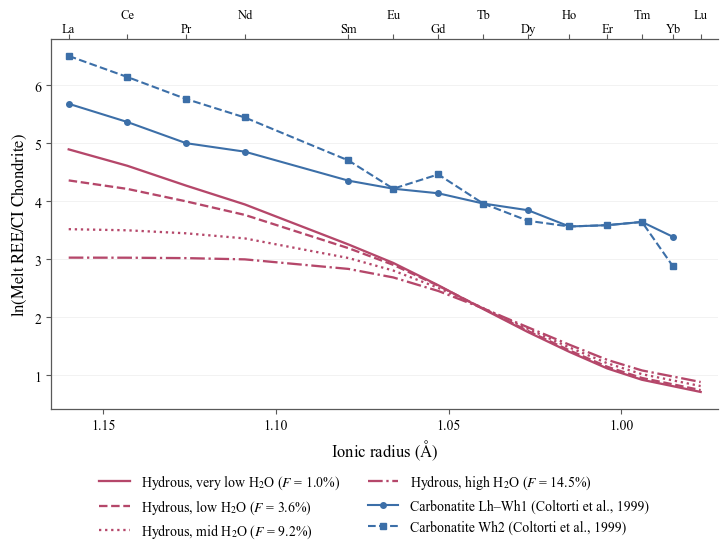

In [7]:
# Figure 6.1
HYDROUS_LINESTYLES = {'very low': '-', 'low': '--', 'mid': ':', 'high': '-.'}
CARBONATITE_MARKERS = {'Lh–Wh1': 'o', 'Wh2': 's'}
with plt.rc_context(THESIS_RC):
    fig, ax = plt.subplots(figsize=(8.6, 4.8))
    for key in HYDROUS:
        a = AGENTS[f'Hydrous, {key} H2O']
        ax.plot(RADII, ln_ci(a['C']), color=AGENT_COLOURS['hydrous'],
                ls=HYDROUS_LINESTYLES[key], lw=1.65,
                label=f"Hydrous, {key} H$_2$O ($F$ = {a['F']:.1%})")
    for key in CARBONATITES:
        a = AGENTS[f'Carbonatite {key}']
        ax.plot(RADII, ln_ci(a['C']), color=AGENT_COLOURS['carbonatite'],
                ls='-' if key == 'Lh–Wh1' else '--', marker=CARBONATITE_MARKERS[key], ms=4,
                lw=1.5, label=f'Carbonatite {key} (Coltorti et al., 1999)')
    ree_axis(ax)
    ax.set(xlabel=RADIUS_LABEL, ylabel=r'$\ln(\mathrm{Melt\ REE}/\mathrm{CI\ Chondrite})$')
    fig.legend(loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=2, handlelength=2.2)
    save(fig, 'metasomatic_agents_lnCI_3GPa_vs_carbonatite')

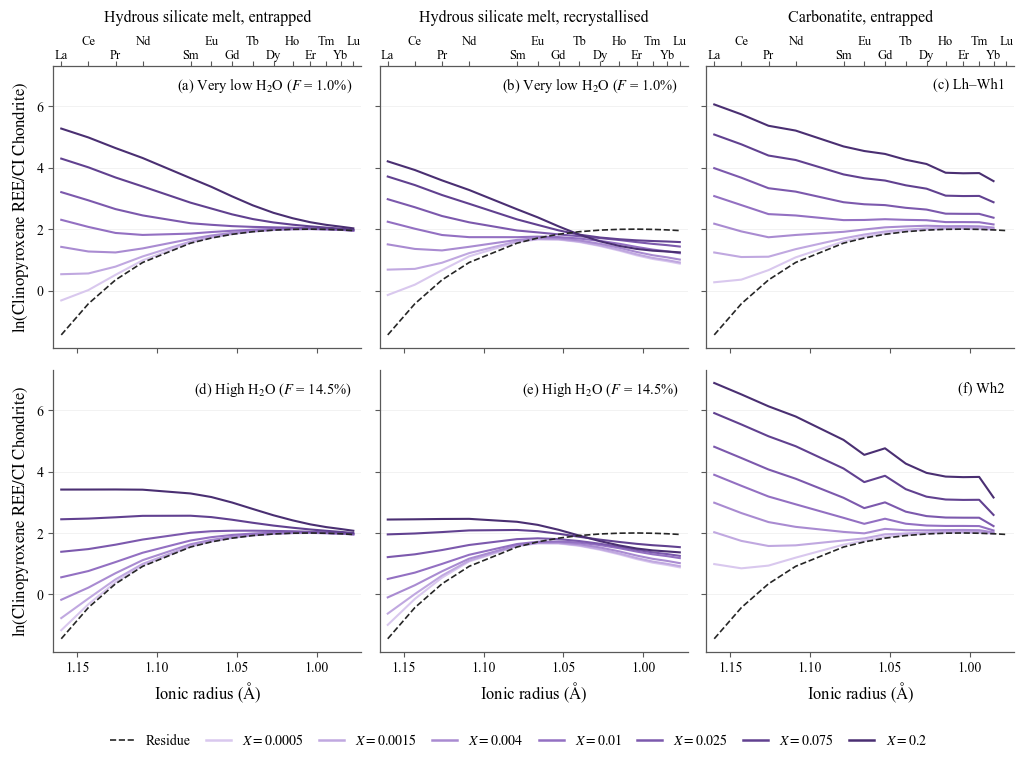

Amphibole  Orthopyroxene  Clinopyroxene  Spinel  Garnet  \
melt         X                                                                 
very low H2O 0.0005        0.1           28.9           10.5     1.8     3.0   
             0.0010        0.3           28.9           10.5     1.8     2.9   
             0.0015        0.4           29.0           10.4     1.8     2.8   
             0.0020        0.6           29.1           10.3     1.8     2.8   
             0.0030        0.8           29.2           10.2     1.8     2.6   
             0.0040        1.1           29.2           10.1     1.7     2.4   
             0.0050        1.4           29.3           10.0     1.7     2.2   
             0.0075        2.1           29.5            9.7     1.7     1.9   
             0.0100        2.7           29.5            9.5     1.7     1.6   
             0.0125        3.2           29.5            9.4     1.7     1.3   
             0.0150        3.5           29.4            9.3     1.7     1.2   
             0.0200        4.1           29.4            9.2     1.7     1.0   
             0.0250        4.6           29.4            9.2     1.7     0.8   
             0.0300        5.2           29.4            9.1     1.7     0.6   
             0.0400        6.3           29.3            8.9     1.7     0.1   
             0.0500        7.3           29.1            8.7     1.6     0.0   
             0.0750        9.9           28.2            8.1     1.4     0.0   
             0.1000       12.4           27.4            7.5     1.3     0.0   
             0.1250       14.9           26.7            7.0     1.1     0.0   
             0.1500       17.2           25.9            6.5     1.0     0.0   
             0.1750       19.0           25.3            6.3     0.9     0.0   
             0.2000       20.8           24.7            6.1     0.9     0.0   
high H2O     0.0005        0.2           28.9           10.5     1.8     3.0   
             0.0010        0.3           28.9           10.4     1.8     2.9   
             0.0015        0.5           29.0           10.4     1.8     2.8   
             0.0020        0.6           29.1           10.3     1.8     2.7   
             0.0030        0.9           29.2           10.2     1.7     2.5   
             0.0040        1.2           29.3           10.0     1.7     2.4   
             0.0050        1.5           29.4            9.9     1.7     2.2   
             0.0075        2.2           29.4            9.6     1.7     1.9   
             0.0100        2.7           29.4            9.5     1.7     1.7   
             0.0125        2.9           29.3            9.5     1.7     1.6   
             0.0150        3.1           29.3            9.5     1.7     1.6   
             0.0200        3.5           29.2            9.5     1.7     1.5   
             0.0250        3.9           29.1            9.4     1.7     1.4   
             0.0300        4.3           29.0            9.4     1.7     1.3   
             0.0400        5.1           28.9            9.4     1.6     1.0   
             0.0500        5.8           28.7            9.3     1.6     0.8   
             0.0750        7.8           28.3            9.3     1.6     0.3   
             0.1000        9.8           27.7            9.1     1.5     0.0   
             0.1250       11.6           27.0            8.9     1.4     0.0   
             0.1500       13.5           26.3            8.7     1.3     0.0   
             0.1750       15.3           25.6            8.6     1.2     0.0   
             0.2000       17.1           24.8            8.5     1.1     0.0   

                     Olivine  ilm  Phlogopite  
melt         X                                 
very low H2O 0.0005     55.6  0.0         0.0  
             0.0010     55.6  0.0         0.0  
             0.0015     55.6  0.0         0.0  
             0.0020     55.5  0.0         0.0  
             0.0030     55.4  0.0         0.0  
    

In [8]:
# Figure 6.2
CH6_AGENTS = ['Hydrous, very low H2O', 'Hydrous, high H2O', 'Carbonatite Lh–Wh1', 'Carbonatite Wh2']
MARK_X = [0.0005, 0.0015, 0.004, 0.01, 0.025, 0.075, 0.2]
mark = np.isin(np.round(X_VALUES, 6), np.round(MARK_X, 6))

ch6 = {(a, m): [metasomatise(res6, AGENTS[a], m, X) for X in X_VALUES] for a in CH6_AGENTS for m in AGENTS[a]['methods']}
COLUMNS = ['Hydrous silicate melt, entrapped', 'Hydrous silicate melt, recrystallised', 'Carbonatite, entrapped']
lo, hi = (f"{k} H$_2$O ($F$ = {AGENTS[f'Hydrous, {k.lower()} H2O']['F']:.1%})" for k in ('Very low', 'High'))
GRID = [[(lo, ('Hydrous, very low H2O', 'entrapped')), (lo, ('Hydrous, very low H2O', 'recrystallised')), ('Lh–Wh1', ('Carbonatite Lh–Wh1', 'entrapped'))],
        [(hi, ('Hydrous, high H2O', 'entrapped')), (hi, ('Hydrous, high H2O', 'recrystallised')), ('Wh2', ('Carbonatite Wh2', 'entrapped'))]]
with plt.rc_context(THESIS_RC):
    fig, axes = plt.subplots(2, 3, figsize=(12.4, 7.6), sharex=True, sharey=True, gridspec_kw={'wspace': 0.06, 'hspace': 0.08})
    for r, row in enumerate(GRID):
        for c, (title, key) in enumerate(row):
            ax = axes[r, c]
            ax.plot(RADII, ln_ci(res6['cpx']), color=RESIDUE_GREY, ls='--', lw=1.2, zorder=4)
            for X, (cpx, _), shown in zip(X_VALUES, ch6[key], mark):
                if shown:
                    ax.plot(RADII, ln_ci(cpx), color=x_colour(X), lw=1.5, zorder=3)
            tag(ax, 3 * r + c, title)
            ree_axis(ax, top=r == 0)
            if r == 0:
                ax.set_title(COLUMNS[c], loc='center', pad=32, fontsize=11.5)
    for ax in axes[1]:
        ax.set_xlabel(RADIUS_LABEL)
    for ax in axes[:, 0]:
        ax.set_ylabel(LN_LABEL)
    h = [Line2D([0], [0], color=RESIDUE_GREY, ls='--', lw=1.2, label='Residue')]
    h += [Line2D([0], [0], color=x_colour(X), lw=1.8, label=f'$X={X:g}$') for X in MARK_X]
    fig.legend(handles=h, loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=8, handlelength=1.8, columnspacing=1.1)
    save(fig, 'metasomatism_three_scenarios')

modes6 = pd.DataFrame({(a.split(', ')[1], X): {ph: 100 * w for ph, w in modes.items()} for a in ('Hydrous, very low H2O', 'Hydrous, high H2O')
                       for X, (_, modes) in zip(X_VALUES, ch6[a, 'recrystallised'])}).T.fillna(0.0)
display(modes6.rename_axis(['melt', 'X']).round(1))

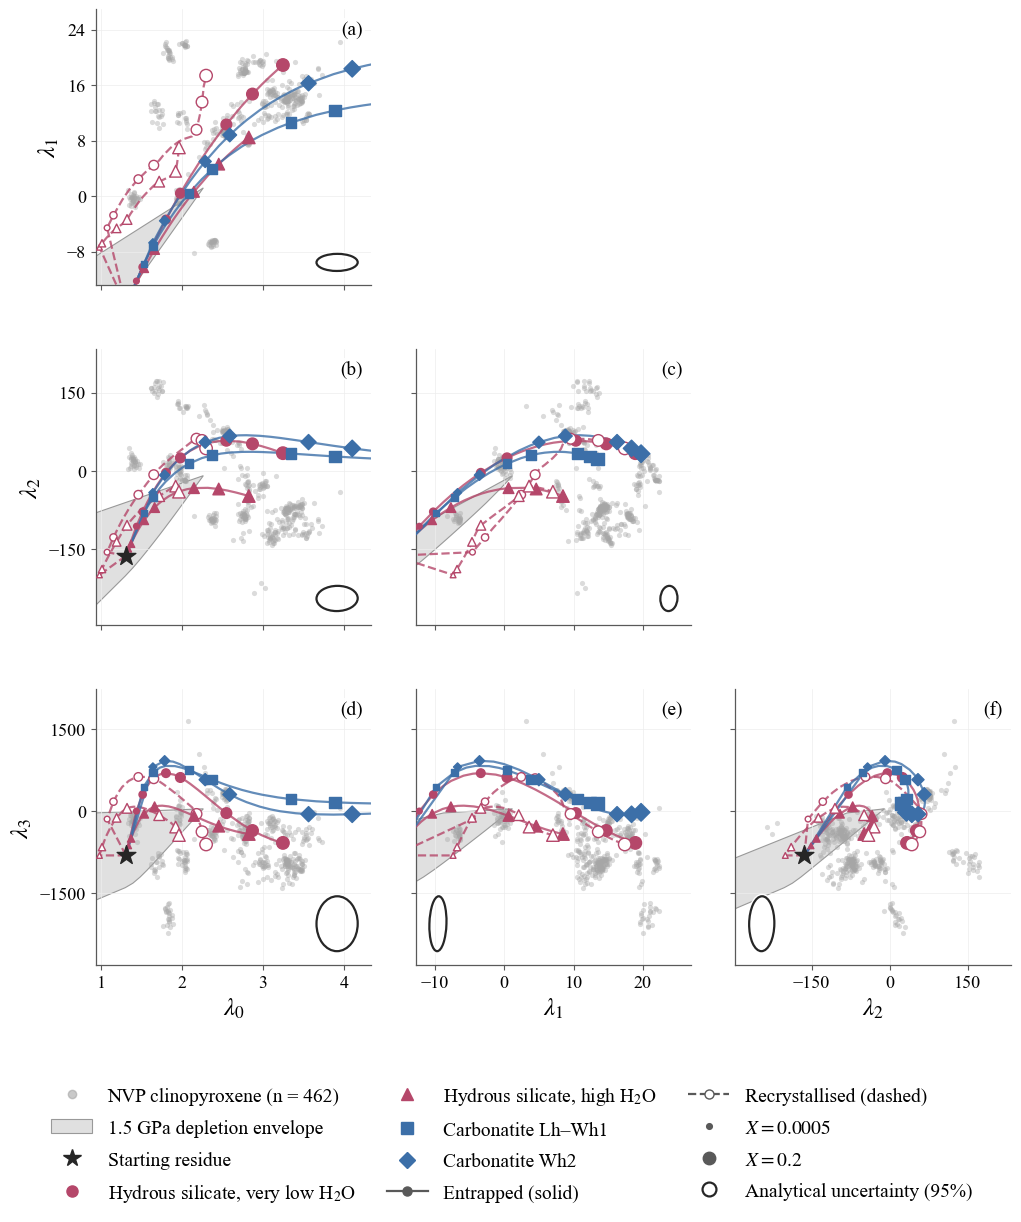

In [9]:
# Figure 6.3
sp = res_all[
    np.isclose(res_all['P_GPa'].astype(float), 1.5)
    & res_all['D_mode'].astype(str).str.lower().eq('variable')
    & res_all['F'].astype(float).between(0, 0.2)
    & (res_all['cpx_solid'] > CPX_TOL)
    & (res_all['spl_solid'] > CPX_TOL)
    & (res_all['g_solid'] < CPX_TOL)
]

envelope = []
for style in ('batch', 'fractional', 'continuous'):
    ppm = sp.loc[
        sp['style'].astype(str).str.strip().str.lower() == style,
        [f'{el}_cpx' for el in REE]
    ].to_numpy(float)
    ppm = ppm[np.isfinite(ppm).all(axis=1) & (ppm > 0).all(axis=1)]
    envelope.append(np.vstack([fit_lambdas(p) for p in ppm]))

envelope = np.vstack(envelope)

MARKERS = dict(zip(CH6_AGENTS, ['o', '^', 's', 'D']))
MARK_X = [0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.2]
mark = np.isin(np.round(X_VALUES, 6), np.round(MARK_X, 6))

SIZES = np.linspace(13, 62, mark.sum())
res_lam = fit_lambdas(res6['cpx'])
traj = {key: np.vstack([fit_lambdas(cpx) for cpx, _ in runs]) for key, runs in ch6.items()}

with plt.rc_context(THESIS_RC):
    fig, panels = corner(3.3)
    fig.set_size_inches(10.4, 12.4)
    fig.subplots_adjust(left=0.1, right=0.98, top=0.985, bottom=0.2, wspace=0.16, hspace=0.16)

    for (i, j), ax in panels.items():
        pts = envelope[:, [i, j]]
        ax.add_patch(plt.Polygon(pts[ConvexHull(pts).vertices], **REGION, zorder=0.5))

        ax.scatter(
            nvp[f'lambda{i}'], nvp[f'lambda{j}'],
            s=14, color=NVP_GREY, alpha=0.4, lw=0, zorder=2
        )

        for (agent, method), lam in traj.items():
            colour = AGENT_COLOURS[AGENTS[agent]['family']]
            entrapped = (method == 'entrapped')

            ax.plot(
                np.r_[res_lam[i], lam[:, i]],
                np.r_[res_lam[j], lam[:, j]],
                color=colour,
                ls='-' if entrapped else '--',
                lw=1.6,
                alpha=0.8,
                zorder=3
            )

            ax.scatter(
                lam[mark, i], lam[mark, j],
                s=SIZES * 1.3,
                marker=MARKERS[agent],
                facecolor=colour if entrapped else 'white',
                edgecolor=colour,
                lw=1.0,
                zorder=4
            )

        ax.scatter(res_lam[i], res_lam[j], marker='*', s=200, color=RESIDUE_GREY, zorder=5)
        add_unc_ellipse(ax, i, j,
                        np.r_[nvp[f'lambda{i}'], res_lam[i], *[lam[:, i] for lam in traj.values()]],
                        np.r_[nvp[f'lambda{j}'], res_lam[j], *[lam[:, j] for lam in traj.values()]],
                        avoid=('upper right',))
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
        ax.tick_params(labelsize=13)
        ax.xaxis.label.set_size(18)
        ax.yaxis.label.set_size(18)

        for t in ax.texts:
            t.set_fontsize(14)

    h = [
        Line2D([], [], ls='', marker='o', ms=6, color=NVP_GREY, alpha=0.6,
               label=f'NVP clinopyroxene (n = {len(nvp)})'),
        Patch(**REGION, label='1.5 GPa depletion envelope'),
        Line2D([], [], ls='', marker='*', ms=13, color=RESIDUE_GREY,
               label='Starting residue')
    ]

    h += [
        Line2D([], [], ls='', marker=mk, ms=8,
               color=AGENT_COLOURS[AGENTS[a]['family']],
               label=a.replace('Hydrous,', 'Hydrous silicate,').replace('H2O', 'H$_2$O'))
        for a, mk in MARKERS.items()
    ]

    h += [
        Line2D([], [], color='0.35', lw=1.6, marker='o', ms=6.5,
               label='Entrapped (solid)'),
        Line2D([], [], color='0.35', lw=1.6, ls='--', marker='o', ms=6.5,
               mfc='white', label='Recrystallised (dashed)')
    ]

    h += [
        Line2D([], [], ls='', marker='o', color='0.35',
               ms=np.sqrt(s * 1.3), label=f'$X = {X:g}$')
        for X, s in ((MARK_X[0], SIZES[0]), (MARK_X[-1], SIZES[-1]))
    ]

    h += [UNC_HANDLE]
    fig.legend(
        handles=h,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.0),
        ncol=3,
        fontsize=14,
        handlelength=2.1,
        columnspacing=1.6,
        labelspacing=0.7
    )

    save(fig, 'lambda_corner_agents')

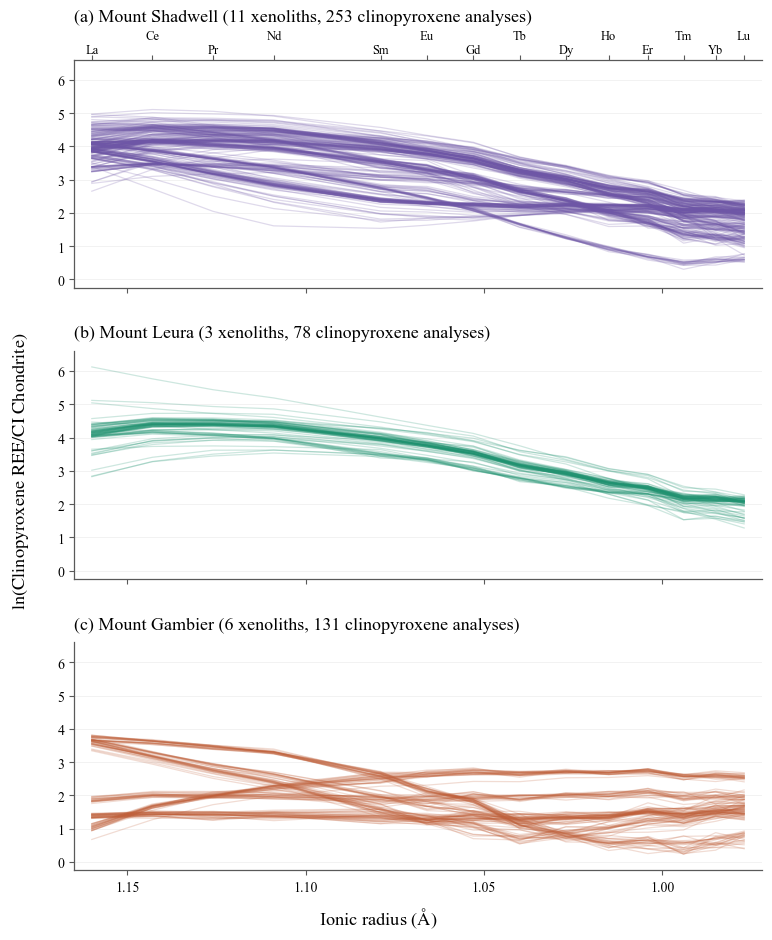

In [10]:
# Figure 7.2
with plt.rc_context(THESIS_RC):
    fig, axes = plt.subplots(3, 1, figsize=(8, 10.0), sharex=True, sharey=True, gridspec_kw={'hspace': 0.28})
    for i, (ax, site) in enumerate(zip(axes, SITES)):
        at = (nvp['Location'] == site).to_numpy()
        ax.plot(RADII, nvp_ln[at].T, color=SITE_COLOURS[site], lw=0.9, alpha=0.22)
        ree_axis(ax, top=i == 0)
        ax.set_ylim(span(nvp_ln, pad=0.08))
        ax.set_title(f"({'abc'[i]}) {mount(site)} ({nvp.loc[at, 'xenolith'].nunique()} xenoliths, {at.sum()} clinopyroxene analyses)",
                     fontsize=13, pad=28 if i == 0 else 10)
    fig.supxlabel(RADIUS_LABEL, y=0.04)
    fig.supylabel(LN_LABEL, x=0.04)
    fig.subplots_adjust(left=0.12, right=0.98, top=0.91, bottom=0.10)
    save(fig, 'ch7_final_samples_spider_by_locality')

In [11]:
# Chapter 7 scenario library and inversion
CH7_RESIDUES = [r for r in (residue(row) for _, row in select(SPL_RESIDUES).iterrows()) if r['modes'].get('Clinopyroxene', 0.0) >= CPX_TOL]
grid_signature = hashlib.sha256(
    Path(MELT_FILE).read_bytes()
    + repr((HYDROUS, PHI, X_VALUES, T_RECRYST)).encode()
).hexdigest()[:10]
GRID_FILE = DATA_FOLDER / (f'ch7_scenarios_{SPL_RESIDUES["D_mode"]}D_recryst{T_RECRYST:.0f}C_'
                           f'X{"-".join(f"{x:g}" for x in X_VALUES)}_{grid_signature}.csv')
if GRID_FILE.exists():
    scen = pd.read_csv(GRID_FILE)
else:
    rows = []
    for r in CH7_RESIDUES:
        for a, agent in AGENTS.items():
            for m in agent['methods']:
                for X in X_VALUES:
                    cpx, modes = metasomatise(r, agent, m, X)
                    rows.append({'F_res': r['F'], 'agent': a, 'family': agent['family'], 'method': m, 'X': X,
                                 **{ph.lower(): modes.get(ph, 0.0) for ph in ('Clinopyroxene', 'Garnet', 'Amphibole')},
                                 **dict(zip(REE, cpx))})
    scen = pd.DataFrame(rows)
    scen.to_csv(GRID_FILE, index=False)
scen = scen[scen['clinopyroxene'] >= CPX_TOL].reset_index(drop=True)
scen['group'] = scen['family'].str.capitalize() + ', ' + scen['method']
scen['label'] = scen['agent'] + ', ' + scen['method']
LABELS = [l for l in (f'{a}, {m}' for a, ag in AGENTS.items() for m in ag['methods']) if l in set(scen['label'])]
model_ln = np.log(scen[REE].to_numpy(float) / CI_ARR)
print(f'{len(CH7_RESIDUES)} residues, {len(scen)} scenarios:', scen['method'].value_counts().to_dict())

TIERS = {'Tier 1': D_CUT, 'Tier 2': D_BROAD}
ORDER = [*TIERS, 'Outside tiers']
D_all = np.vstack([misfit(p, model_ln) for p in nvp_ppm])
res_ln = ln_ci(np.vstack([r['cpx'] for r in CH7_RESIDUES]))
inv, acc = [], []
for k, d in enumerate(D_all):
    best = int(np.argmin(d))
    tier = next((t for t, cut in TIERS.items() if d[best] <= cut), 'Outside tiers')
    ok = np.flatnonzero(d <= TIERS[tier]) if tier in TIERS else np.array([], int)
    inv.append({'D_min': d[best], 'fit_tier': tier, 'best': best, 'n_accepted': len(ok), 'D_min, no melt': misfit(nvp_ppm[k], res_ln).min()})
    acc.append(pd.DataFrame({'analysis': k, 'fit_tier': tier, 'scenario': ok, 'weight': 1 / max(len(ok), 1)}))
SCEN_COLS = ['label', 'group', 'method', 'X', 'F_res', 'garnet', 'amphibole']
inv = nvp[['analysis_id', 'Location', 'xenolith']].join(pd.DataFrame(inv)).join(scen[SCEN_COLS], on='best')
inv['tier, all X'] = pd.Categorical(inv['fit_tier'], ORDER)
acc = pd.concat(acc, ignore_index=True).join(scen[SCEN_COLS], on='scenario').join(inv[['Location', 'xenolith']], on='analysis')

print(f'Tier 1: D_min <= {D_CUT:.2f} | Tier 2: {D_CUT:.2f} < D_min <= {D_BROAD:g}')
display(pd.crosstab(inv['Location'], inv['tier, all X'], margins=True, dropna=False))
fit = inv[inv['fit_tier'] != 'Outside tiers']
display(pd.crosstab([fit['Location'], fit['fit_tier']], fit['label']).reindex(columns=[l for l in LABELS if l in set(fit['label'])]))
print('Median D_min with metasomatism and with depletion alone:')
display(inv.groupby('Location')[['D_min', 'D_min, no melt']].median().round(1))

40 residues, 8800 scenarios: {'entrapped': 5280, 'recrystallised': 3520}
Tier 1: D_min <= 3.08 | Tier 2: 3.08 < D_min <= 6


"tier, all X",Tier 1,Tier 2,Outside tiers,All
Location,,,,
Mt Gambier,62,23,46,131
Mt Leura,49,17,12,78
Mt Shadwell,81,81,91,253
All,192,121,149,462


label                 Hydrous, very low H2O, entrapped  \
Location    fit_tier                                     
Mt Gambier  Tier 1                                   2   
            Tier 2                                   2   
Mt Leura    Tier 1                                   0   
            Tier 2                                   0   
Mt Shadwell Tier 1                                   9   
            Tier 2                                   0   

label                 Hydrous, very low H2O, recrystallised  \
Location    fit_tier                                          
Mt Gambier  Tier 1                                        0   
            Tier 2                                       11   
Mt Leura    Tier 1                                        0   
            Tier 2                                        0   
Mt Shadwell Tier 1                                        0   
            Tier 2                                        0   

label                 Hydrous, low H2O, entrapped  \
Location    fit_tier                                
Mt Gambier  Tier 1                             14   
            Tier 2                              8   
Mt Leura    Tier 1                              0   
            Tier 2                              0   
Mt Shadwell Tier 1                              6   
            Tier 2                              0   

label                 Hydrous, low H2O, recrystallised  \
Location    fit_tier                                     
Mt Gambier  Tier 1                                   0   
            Tier 2                                   2   
Mt Leura    Tier 1                                   0   
            Tier 2                                   0   
Mt Shadwell Tier 1                                   0   
            Tier 2                                  15   

label                 Hydrous, mid H2O, entrapped  \
Location    fit_tier                                
Mt Gambier  Tier 1                             12   
            Tier 2                              0   
Mt Leura    Tier 1                              9   
            Tier 2                              0   
Mt Shadwell Tier 1                              4   
            Tier 2                              7   

label                 Hydrous, mid H2O, recrystallised  \
Location    fit_tier                                     
Mt Gambier  Tier 1                                   3   
            Tier 2                                   0   
Mt Leura    Tier 1                                   0   
            Tier 2                                   0   
Mt Shadwell Tier 1                                   0   
            Tier 2                                   0   

label                 Hydrous, high H2O, entrapped  \
Location    fit_tier                                 
Mt Gambier  Tier 1                               2   
            Tier 2                               0   
Mt Leura    Tier 1                              40   
            Tier 2                              17   
Mt Shadwell Tier 1                              20   
            Tier 2                              55   

label                 Hydrous, high H2O, recrystallised  \
Location    fit_tier                                      
Mt Gambier  Tier 1                                   29   
            Tier 2                                    0   
Mt Leura    Tier 1                                    0   
            Tier 2                                    0   
Mt Shadwell Tier 1                                    0   
            Tier 2                                    0   

label                 Carbonatite Lh–Wh1, entrapped  \
Location    fit_tier                                  
Mt Gambier  Tier 1                                0   
            Tier 2                                0   
Mt Leura    Tier 1                                0   
            Tier 2                                0   
Mt Shadwell Ti

Median D_min with metasomatism and with depletion alone:


,D_min,"D_min, no melt"
Location,,
Mt Gambier,3.4,24.4
Mt Leura,2.6,48.4
Mt Shadwell,4.4,42.8


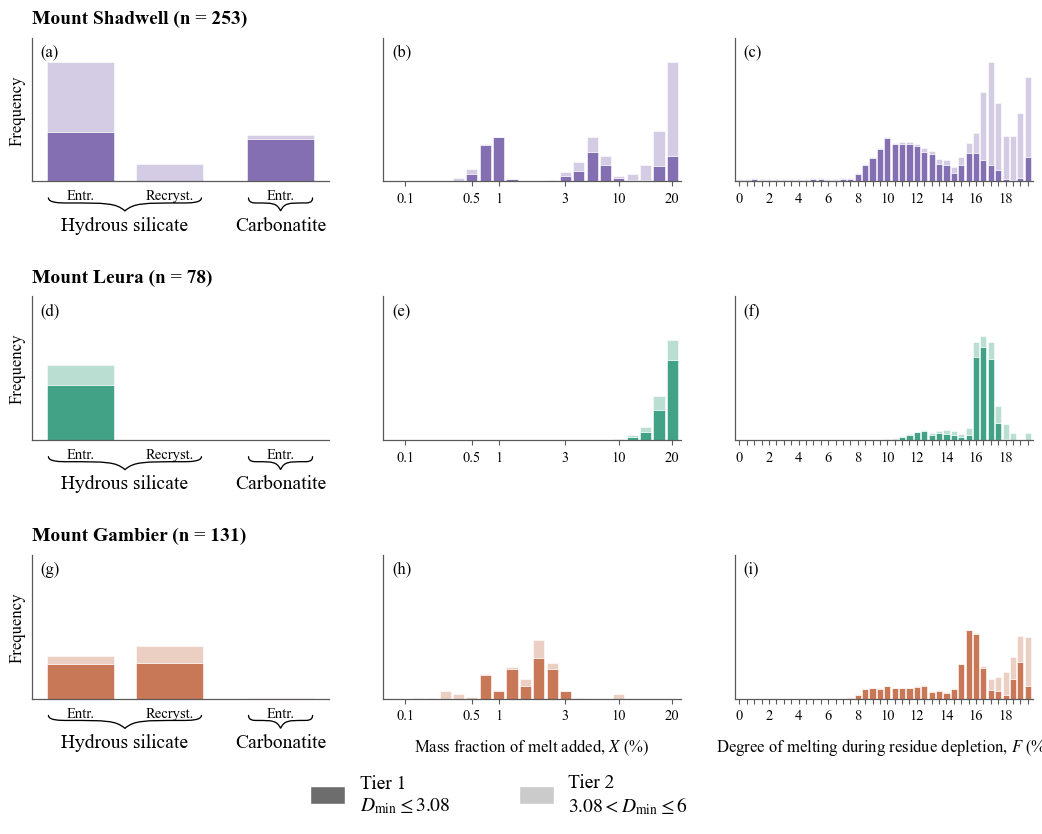

In [12]:
# Figure 7.6
TIER_ALPHA = {'Tier 1': 0.85, 'Tier 2': 0.30}
METHOD_SHORT = {'entrapped': 'Entr.', 'recrystallised': 'Recryst.'}
GROUPS = [g for g in (f'{f}, {m}' for f in ('Hydrous', 'Carbonatite') for m in METHOD_SHORT) if g in set(scen['group'])]
GROUP_X = np.arange(len(GROUPS)) + 0.25 * np.array([g.startswith('Carbonatite') for g in GROUPS])
X_TICKS = {i: f'{100 * x:g}' for i, x in enumerate(X_VALUES) if np.isclose(x, [0.001, 0.005, 0.01, 0.03, 0.1, 0.2, 0.3]).any()}
f_levels = sorted(scen['F_res'].unique())
F_TICKS = [f'{100 * f:g}' if i % int(np.ceil(len(f_levels) / 11)) == 0 else '' for i, f in enumerate(f_levels)]
PANELS = [('group', GROUPS), ('X', X_VALUES), ('F_res', f_levels)]
WIDTHS = [1.2, 1.2, 1.2]

def underbrace(ax, x0, x1, label, y):
    mid, w = (x0 + x1) / 2, x1 - x0
    xs = [x0, x0, x0 + .08 * w, x0 + .12 * w, mid - .12 * w, mid - .06 * w, mid, mid + .06 * w, mid + .12 * w, x1 - .12 * w,
          x1 - .08 * w, x1, x1]
    ys = [y + .035] + [y] * 5 + [y - .055] + [y] * 5 + [y + .035]
    tr = blended_transform_factory(ax.transData, ax.transAxes)
    ax.add_patch(PathPatch(MplPath(list(zip(xs, ys)), [MplPath.MOVETO] + [MplPath.CURVE4] * 12), transform=tr, fill=False,
                           edgecolor='black', lw=0.95, capstyle='round', clip_on=False))
    ax.text(mid, y - .09, label, transform=tr, ha='center', va='top', fontsize=14, clip_on=False)

def stacked(ax, data, key, levels, colour, labels=True, brace_y=-0.15):
    xs = GROUP_X if key == 'group' else np.arange(len(levels))
    bottom = np.zeros(len(levels))
    for tier, alpha in TIER_ALPHA.items():
        h = data.loc[data['fit_tier'] == tier].groupby(key)['weight'].sum().reindex(levels, fill_value=0).to_numpy()
        ax.bar(xs, h, bottom=bottom, width=0.75 if key == 'group' else 0.83, color=to_rgba(colour, alpha), edgecolor='white', lw=0.4)
        bottom += h
    if key == 'group':
        ax.set_xticks(xs, [METHOD_SHORT[g.split(', ')[1]] for g in levels])
        ax.set_xlim(xs[0] - 0.55, xs[-1] + 0.55)
        ax.tick_params(axis='x', length=0, pad=5)
        for agent, name in (('Hydrous', 'Hydrous silicate'), ('Carbonatite', 'Carbonatite')):
            x = xs[[g.startswith(agent) for g in levels]]
            if labels and len(x):
                underbrace(ax, x[0] - .36, x[-1] + .36, name, brace_y)
    else:
        ax.set_xticks(*zip(*X_TICKS.items())) if key == 'X' else ax.set_xticks(np.arange(len(levels)), F_TICKS)
        ax.set_xlim(-0.65, len(levels) - 0.35)
    ax.tick_params(axis='x', labelsize=10.5, labelbottom=labels)
    ax.tick_params(axis='y', left=False, labelleft=False)
    return bottom.max()

def finish(fig, axes, legend_y):
    axes[-1, 1].set_xlabel(X_LABEL, labelpad=10)
    axes[-1, 2].set_xlabel(F_LABEL, labelpad=10)
    fig.legend(handles=[Patch(facecolor=to_rgba('0.33', TIER_ALPHA['Tier 1']), edgecolor='white',
                              label=f'Tier 1\n$D_{{\\min}} \\leq {D_CUT:.2f}$'),
                        Patch(facecolor=to_rgba('0.33', TIER_ALPHA['Tier 2']), edgecolor='white',
                              label=f'Tier 2\n${D_CUT:.2f} < D_{{\\min}} \\leq {D_BROAD:g}$')],
               loc='lower center', bbox_to_anchor=(0.5, legend_y), ncol=2, fontsize=14, handlelength=1.8, handleheight=1.1,
               handletextpad=0.75, columnspacing=3.5)

with plt.rc_context(THESIS_RC):
    fig, axes = plt.subplots(len(SITES), 3, figsize=(11.0, 8.7), sharey='col',
                             gridspec_kw={'width_ratios': WIDTHS, 'wspace': 0.18, 'hspace': 0.8})
    top = np.zeros(3)
    for i, site in enumerate(SITES):
        for j, (key, levels) in enumerate(PANELS):
            top[j] = max(top[j], stacked(axes[i, j], acc[acc['Location'] == site], key, levels, SITE_COLOURS[site]))
            axes[i, j].text(
    0.03, 0.96,
    f'({chr(97 + 3*i + j)})',
    transform=axes[i, j].transAxes,
    ha='left', va='top',
    fontsize=12,
    fontweight='normal'
)
        axes[i, 0].text(0, 1.08, f"{mount(site)} (n = {(inv['Location'] == site).sum()})", transform=axes[i, 0].transAxes,
                        va='bottom', fontsize=14, fontweight='bold')
        axes[i, 0].set_ylabel('Frequency')
    for j in range(3):
        axes[0, j].set_ylim(0, 1.2 * top[j])
    finish(fig, axes, 0.035)
    fig.subplots_adjust(left=0.075, right=0.985, top=0.95, bottom=0.19)
    save(fig, f'ch7_NVP_inversion_histograms_by_location_T{T_RECRYST:.0f}C')

\
               Location analyses Tier 1 Tier 2   
MSHAD_AA_1  Mt Shadwell       13      8      4   
MSHAD_AA_2  Mt Shadwell       15      0     15   
MSHAD_AA_3  Mt Shadwell       14     12      0   
MSHAD_AA_4  Mt Shadwell       10     10      0   
MSHAD_AA_5  Mt Shadwell       29     29      0   
70984       Mt Shadwell       26      0      0   
70994       Mt Shadwell       17     14      3   
71002          Mt Leura       21      0      9   
71008a         Mt Leura       13      9      4   
71008b         Mt Leura       44     40      4   
76996       Mt Shadwell       21      5     16   
76997       Mt Shadwell       32      0      0   
76998       Mt Shadwell       25      0     13   
76999       Mt Shadwell       51      3     30   
MG_SA_1      Mt Gambier       32     32      0   
MG_SA_2      Mt Gambier       24      0      0   
MG_SA_3      Mt Gambier       23      0      2   
MG_SA_5      Mt Gambier       13     11      2   
MG_SA_6      Mt Gambier       19      0     18   
MG_SA_7      Mt Gambier       20     19      1   

                                          hydrous                       \
                                         scenario      X residue F (%)   
MSHAD_AA_1       Hydrous, very low H2O, entrapped  0.030          12.0   
MSHAD_AA_2       Hydrous, low H2O, recrystallised  0.200          19.5   
MSHAD_AA_3            Hydrous, low H2O, entrapped  0.075          11.0   
MSHAD_AA_4       Hydrous, very low H2O, entrapped  0.050           8.5   
MSHAD_AA_5       Hydrous, very low H2O, entrapped  0.050           9.0   
70984                Hydrous, high H2O, entrapped  0.150          17.0   
70994                Hydrous, high H2O, entrapped  0.200           9.5   
71002                Hydrous, high H2O, entrapped  0.150          17.0   
71008a                Hydrous, mid H2O, entrapped  0.175          13.0   
71008b               Hydrous, high H2O, entrapped  0.200          16.5   
76996                 Hydrous, mid H2O, entrapped  0.050          19.0   
76997                Hydrous, high H2O, entrapped  0.050          19.0   
76998                Hydrous, high H2O, entrapped  0.200          17.0   
76999                Hydrous, high H2O, entrapped  0.200          17.0   
MG_SA_1         Hydrous, high H2O, recrystallised  0.020          16.0   
MG_SA_2              Hydrous, high H2O, entrapped  0.015           4.5   
MG_SA_3          Hydrous, low H2O, recrystallised  0.100          19.5   
MG_SA_5               Hydrous, low H2O, entrapped  0.008          19.0   
MG_SA_6     Hydrous, very low H2O, recrystallised  0.020          18.0   
MG_SA_7               Hydrous, low H2O, entrapped  0.012           9.5   

                                       carbonatite                       \
           median D                       scenario      X residue F (%)   
MSHAD_AA_1    5.389     Carbonatite Wh2, entrapped  0.005          13.5   
MSHAD_AA_2    3.959     Carbonatite Wh2, entrapped  0.002          19.0   
MSHAD_AA_3    6.504  Carbonatite Lh–Wh1, entrapped  0.008          17.5   
MSHAD_AA_4    3.440  Carbonatite Lh–Wh1, entrapped  0.010          15.5   
MSHAD_AA_5    3.464  Carbonatite Lh–Wh1, entrapped  0.010          15.5   
70984         8.407  Carbonatite Lh–Wh1, entrapped  0.025          15.5   
70994         2.354  Carbonatite Lh–Wh1, entrapped  0.030           2.0   
71002        10.719  Carbonatite Lh–Wh1, entrapped  0.030          16.5   
71008a        1.708  Carbonatite Lh–Wh1, entrapped  0.020          16.0   
71008b        2.873  Carbonatite Lh–Wh1, entrapped  0.030          15.5   
76996         5.054     Carbonatite Wh2, entrapped  0.010          17.5   
76997         9.280  Carbonatite Lh–Wh1, entrapped  0.010          18.0   
76998        11.600  Carbonatite Lh–Wh1, entrapped  0.075           6.5   
76999         5.885  Carbonatite Lh–Wh1, entrapped  0.040          14.5   
MG_SA_1       1.943  Carbonatite Lh–Wh1, entrapped  0.001          17.0   
MG_SA_2      14.815  Carbonatite Lh–Wh1, en

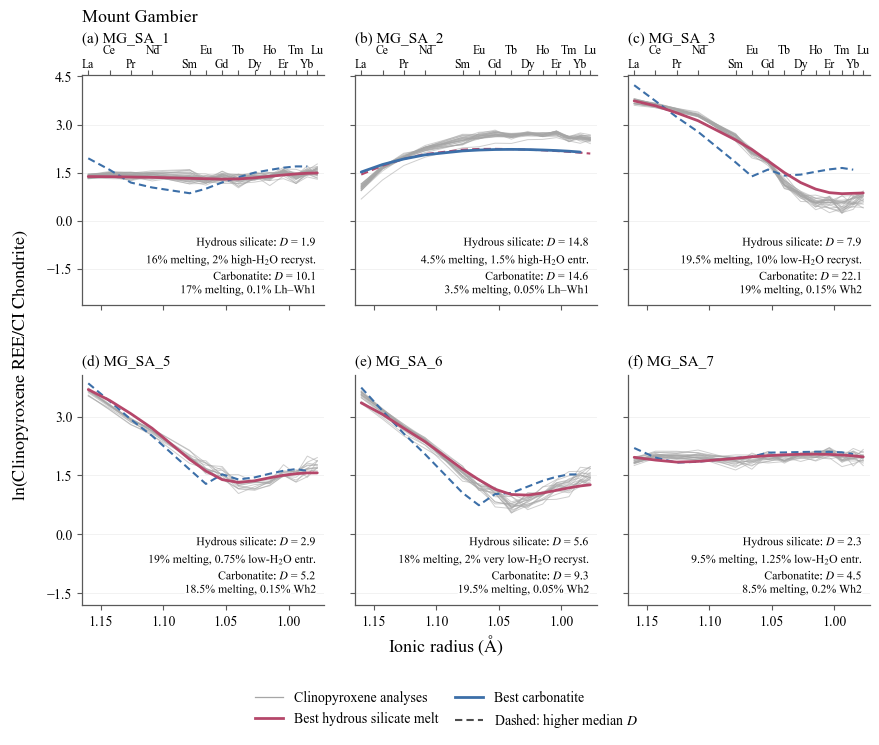

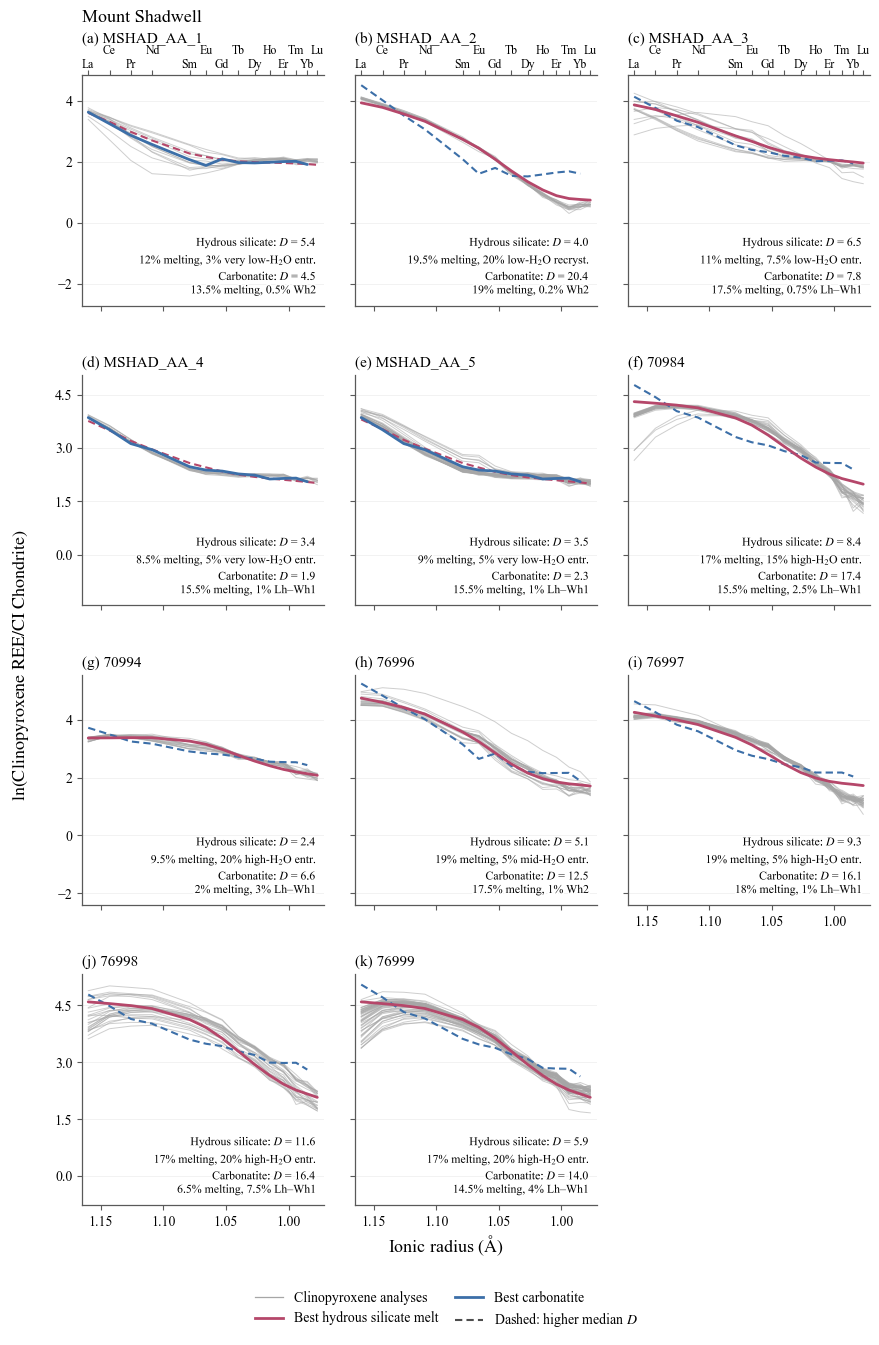

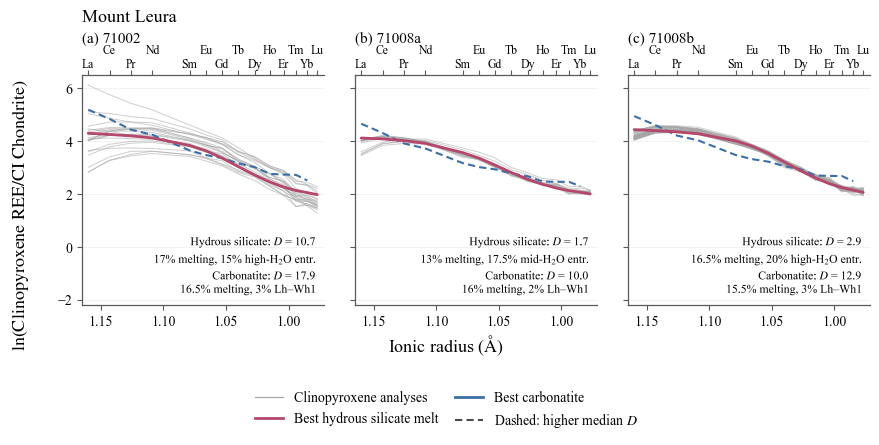

In [13]:
# Figures 7.3 to 7.5
FAMILIES = {'hydrous': 'Hydrous silicate melt', 'carbonatite': 'Carbonatite'}
LOC_ORDER = ['Mt Gambier', 'Mt Shadwell', 'Mt Leura']
FIG_W, ROW_H = 9.0, 3.0

rows, sample_at = {}, {}
for s in SAMPLES:
    at = np.flatnonzero(inv['xenolith'] == s.upper())
    if not len(at):
        continue
    tiers = inv['fit_tier'].iloc[at]
    row = {('', 'Location'): inv['Location'].iloc[at[0]], ('', 'analyses'): len(at),
           ('', 'Tier 1'): int((tiers == 'Tier 1').sum()), ('', 'Tier 2'): int((tiers == 'Tier 2').sum())}
    for fam in FAMILIES:
        cols = np.flatnonzero((scen['family'] == fam).to_numpy())
        med = np.median(D_all[np.ix_(at, cols)], axis=0)
        sc = scen.iloc[cols[np.argmin(med)]]
        row.update({(fam, 'scenario'): sc['label'], (fam, 'X'): sc['X'], (fam, 'residue F (%)'): 100 * sc['F_res'],
                    (fam, 'median D'): med.min(), (fam, 'line'): int(cols[np.argmin(med)])})
    row[('', 'lower D')] = min(FAMILIES, key=lambda f: row[(f, 'median D')])
    rows[s], sample_at[s] = row, at
samples = pd.DataFrame.from_dict(rows, orient='index')
samples.columns = pd.MultiIndex.from_tuples(samples.columns)
show = samples.drop(columns=[(f, 'line') for f in FAMILIES])
display(show.round(3))


def history(t, fam):
    lab = t[(fam, 'scenario')]
    melt = (lab.split(', ')[1].replace(' H2O', '-H$_2$O') + (' recryst.' if 'recryst' in lab else ' entr.')
            if fam == 'hydrous' else lab.split(', ')[0].replace('Carbonatite ', ''))
    return f"{t[(fam, 'residue F (%)')]:g}% melting, {100 * t[(fam, 'X')]:g}% {melt}"

for site in LOC_ORDER:
    t_site = samples[samples[('', 'Location')] == site]
    if t_site.empty:
        continue
    n_rows = int(np.ceil(len(t_site) / 3))
    H = ROW_H * n_rows + 1.7
    with plt.rc_context(THESIS_RC):
        fig, axes = plt.subplots(n_rows, 3, figsize=(FIG_W, H), sharex=True, sharey='row', squeeze=False)
        fig.subplots_adjust(left=0.095, right=0.97, top=1 - 0.95 / H, bottom=1.45 / H, wspace=0.13, hspace=0.30)
        first_ax = axes[0, 0]
        pos = first_ax.get_position()

        fig.text(
            pos.x0,
            pos.y1 + 0.65 / H,
            mount(site),
            ha='left',
            va='top',
            fontsize=13,
            fontweight='normal'
        )
        ylims = []
        for k, ax in enumerate(axes.flat):
            row, col = divmod(k, 3)
            if k >= len(t_site):
                ax.set_visible(False)
                continue
            s, t = t_site.index[k], t_site.iloc[k]
            ax.plot(RADII, nvp_ln[sample_at[s]].T, color=NVP_GREY, lw=0.7, alpha=0.55, zorder=2)
            for fam in FAMILIES:
                better = fam == t[('', 'lower D')]
                ax.plot(RADII, model_ln[int(t[(fam, 'line')])], color=AGENT_COLOURS[fam], ls='-' if better else (0, (3.5, 2)),
                        lw=2.0 if better else 1.5, solid_capstyle='round', zorder=5 if better else 4)
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', RuntimeWarning)
                ylims.append(span(nvp_ln[sample_at[s]], model_ln[[int(t[(f, 'line')]) for f in FAMILIES]], pad=0.08))
            ree_axis(ax, top=row == 0, fontsize=8.5)
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
            ax.tick_params(length=3.5, width=0.8, labelsize=10, labelbottom=k + 3 >= len(t_site), labelleft=col == 0)
            ax.set_title(f"({string.ascii_lowercase[k]}) {s}", loc='left', fontsize=11, pad=23 if row == 0 else 6)
            ax.text(0.97, 0.04, '\n'.join(f"{FAMILIES[f].replace(' melt', '')}: $D$ = {t[(f, 'median D')]:.1f}\n{history(t, f)}"
                                          for f in FAMILIES),
                    transform=ax.transAxes, ha='right', va='bottom', fontsize=8.5, linespacing=1.15, zorder=10,
                    path_effects=[pe.withStroke(linewidth=2.5, foreground='white')])
        for row in range(n_rows):
            lo = min(l[0] for l in ylims[3 * row:3 * row + 3])
            hi = max(l[1] for l in ylims[3 * row:3 * row + 3])
            axes[row, 0].set_ylim(lo - 0.55 * (hi - lo), hi)
        fig.legend(handles=[Line2D([0], [0], color=NVP_GREY, lw=0.9)] + [Line2D([0], [0], color=c, lw=2.0) for c in AGENT_COLOURS.values()]
                           + [Line2D([0], [0], color='0.3', ls=(0, (3.5, 2)), lw=1.5)],
                   labels=['Clinopyroxene analyses', 'Best hydrous silicate melt', 'Best carbonatite', 'Dashed: higher median $D$'],
                   loc='lower center', bbox_to_anchor=(0.5, 0.08 / H), ncol=2, fontsize=10, columnspacing=1.2, handlelength=2.0)
        fig.supxlabel(RADIUS_LABEL, y=0.92 / H, fontsize=13)
        fig.supylabel(LN_LABEL, x=0.015, fontsize=13)
        stem = f"ch7_{site.replace(' ', '_')}_by_sample_hydrous_vs_carbonatite_T{T_RECRYST:.0f}C"
        fig.savefig(FIGURE_FOLDER / f'{stem}.pdf', bbox_inches='tight')
        fig.savefig(FIGURE_FOLDER / f'{stem}.png', dpi=600, bbox_inches='tight')
        plt.show()

Ti/Eu field agrees with the best-fitting agent: 115 of 313


field                     carbonatitic  silicate  All
type         best fit                                
Flat HREE    carbonatite             0        46   46
             hydrous                 2        15   17
Gambier-type hydrous                 0        83   83
Humped       hydrous               133        17  150
Low HREE     hydrous                17         0   17
All                                152       161  313

count   25%   50%    75%
type         field                                 
Flat HREE    carbonatitic    2.0  57.0  59.0   62.0
             silicate       61.0  26.0  27.0   40.0
Gambier-type silicate       83.0  31.0  34.0   40.0
Humped       carbonatitic  133.0  55.0  74.0  144.0
             silicate       17.0  34.0  35.0   37.0
Low HREE     carbonatitic   17.0  35.0  36.0   37.0

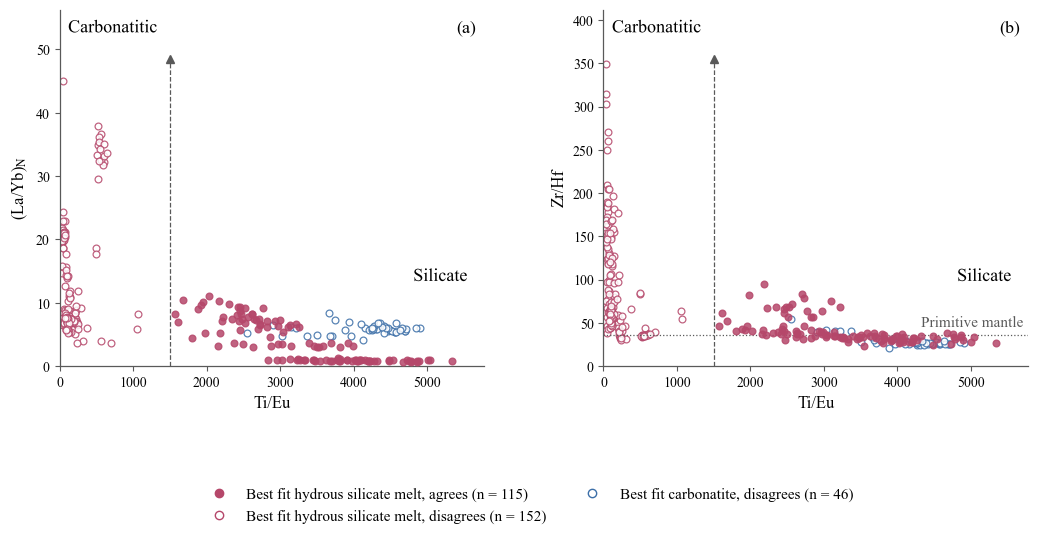

In [14]:
# Figure 7.7
TI_EU_CUT, ZRHF_PM, TREND_GREY = 1500, 36, '0.35'

dia = nvp[['analysis_id', 'La', 'Eu', 'Yb']].merge(raw_col('Ti'), on=['analysis_id', 'La'], how='left')
dia['Ti/Eu'] = dia['Ti'] / dia['Eu']
dia['(La/Yb)N'] = (dia['La'] / CI_ARR[REE.index('La')]) / (dia['Yb'] / CI_ARR[REE.index('Yb')])
dia['field'] = np.where(dia['Ti/Eu'] < TI_EU_CUT, 'carbonatitic', 'silicate')
dia['best fit'] = scen['family'].to_numpy()[inv['best'].to_numpy(int)]
dia = dia.join(inv[['xenolith', 'fit_tier']])
ok = np.isfinite(dia['Ti/Eu']) & np.isfinite(dia['(La/Yb)N']) & dia[['Ti/Eu', '(La/Yb)N']].gt(0).all(axis=1)
d = dia.loc[ok & dia['fit_tier'].isin(['Tier 1', 'Tier 2'])].copy()
field_agent = d['field'].map({'carbonatitic': 'carbonatite', 'silicate': 'hydrous'})
d['agreement'] = np.where(field_agent == d['best fit'], 'match', 'mismatch')

zh = nvp[['analysis_id', 'La']].merge(
    raw_col('Zr'), on=['analysis_id', 'La'], how='left'
).merge(
    raw_col('Hf'), on=['analysis_id', 'La'], how='left'
)

d['Zr/Hf'] = (zh['Zr'] / zh['Hf']).reindex(d.index)
d['type'] = pattern_of(d)

print(f"Ti/Eu field agrees with the best-fitting agent: {(d['agreement'] == 'match').sum()} of {len(d)}")
display(pd.crosstab([d['type'], d['best fit']], d['field'], margins=True))
display(
    d.groupby(['type', 'field'])['Zr/Hf']
    .describe()[['count', '25%', '50%', '75%']]
    .round(0)
)

n = d.groupby(['best fit', 'agreement']).size()

with plt.rc_context(THESIS_RC):
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(12.5, 5.4))

    kw = dict(
        va='top', fontsize=13, zorder=5,
        path_effects=[
            pe.withStroke(linewidth=2.5, foreground='white')
        ]
    )

    xmax = dia.loc[ok, 'Ti/Eu'].quantile(0.995) * 1.05

    for (fam, agr), g in d.groupby(['best fit', 'agreement']):
        c = AGENT_COLOURS[fam]
        sty = dict(
            s=24,
            facecolor=c if agr == 'match' else 'white',
            edgecolor=c,
            lw=0.9,
            alpha=0.85,
            zorder=3 if agr == 'match' else 2
        )
        ax.scatter(g['Ti/Eu'], g['(La/Yb)N'], **sty)

        gz = g[g['Zr/Hf'].gt(0)]
        bx.scatter(gz['Ti/Eu'], gz['Zr/Hf'], **sty)

    ax.set(
        ylim=(0, dia.loc[ok, '(La/Yb)N'].max() * 1.25),
        xlim=(0, xmax),
        xlabel='Ti/Eu',
        ylabel=r'(La/Yb)$_\mathrm{N}$'
    )

    bx.axhline(ZRHF_PM, color='0.35', ls=':', lw=0.9)
    bx.annotate(
        'Primitive mantle',
        (1.0, ZRHF_PM),
        xycoords=('axes fraction', 'data'),
        xytext=(-4, 4),
        textcoords='offset points',
        ha='right', va='bottom',
        fontsize=11, color='0.35'
    )

    bx.set(
        xlim=(0, xmax),
        xlabel='Ti/Eu',
        ylabel='Zr/Hf',
        ylim=(0, d['Zr/Hf'].quantile(0.995) * 1.25)
    )

    for a, letter in ((ax, '(a)'), (bx, '(b)')):

        a.plot(
            [TI_EU_CUT, TI_EU_CUT], [0, 0.86],
            transform=a.get_xaxis_transform(),
            color=TREND_GREY, ls='--', lw=0.9, zorder=1
        )
        a.plot(
            TI_EU_CUT, 0.86,
            transform=a.get_xaxis_transform(),
            marker='^', ms=6, color=TREND_GREY, zorder=1
        )

        a.text(
            0.02, 0.97, 'Carbonatitic',
            transform=a.transAxes,
            ha='left', **kw
        )

        a.text(
            0.96, 0.25, 'Silicate',
            transform=a.transAxes,
            ha='right', va='center',
            fontsize=13, zorder=5,
            path_effects=[
                pe.withStroke(linewidth=2.5, foreground='white')
            ]
        )

        a.text(
            0.98, 0.97, letter,
            transform=a.transAxes,
            ha='right', va='top', fontsize=13
        )

    h = [
        Line2D(
            [0], [0], ls='', marker='o', ms=6,
            mec=AGENT_COLOURS[fam],
            mfc=AGENT_COLOURS[fam] if agr == 'match' else 'white',
            label=(
                f"Best fit {FAMILIES[fam].lower()}, "
                f"{'agrees' if agr == 'match' else 'disagrees'} "
                f"(n = {n.get((fam, agr), 0)})"
            )
        )
        for fam in ('hydrous', 'carbonatite')
        for agr in ('match', 'mismatch')
        if n.get((fam, agr), 0)
    ]

    fig.legend(
        handles=h,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.02),
        ncol=2,
        fontsize=11
    )

    fig.subplots_adjust(wspace=0.28, bottom=0.22)

    save(fig, 'ch7_NVP_TiEu_LaYb_ZrHf_vs_best_fit')

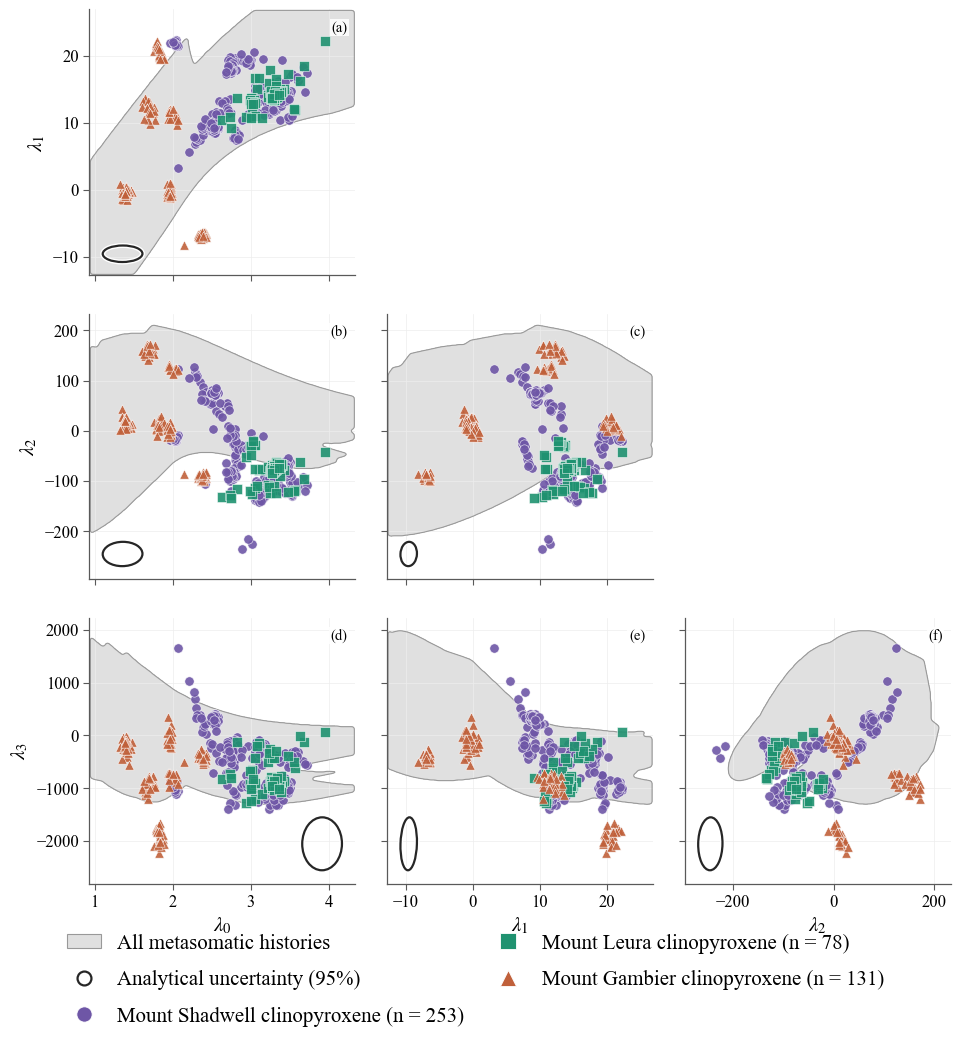

In [15]:
# Figure 7.8
N_PIX = 400

scen_lam = np.vstack([
    fit_lambdas(c)
    for c in scen[REE].to_numpy(float)
])

GRIDS = []

for _, sub in scen.groupby('label'):
    f_lv = np.sort(sub['F_res'].unique())
    x_lv = np.sort(sub['X'].unique())

    g = np.full((len(f_lv), len(x_lv), 4), np.nan)

    g[
        np.searchsorted(f_lv, sub['F_res']),
        np.searchsorted(x_lv, sub['X'])
    ] = scen_lam[sub.index]

    GRIDS.append(g)


def region(i, j, gx, gy):

    mask = np.zeros((N_PIX, N_PIX), bool)
    step = np.array([gx[1] - gx[0], gy[1] - gy[0]])
    top = N_PIX - 1

    for g in GRIDS:
        p = (g[:, :, [i, j]] - [gx[0], gy[0]]) / step

        for a, b in np.ndindex(
            p.shape[0] - 1,
            p.shape[1] - 1
        ):
            c = p[a:a + 2, b:b + 2].reshape(4, 2)

            if (
                not np.isfinite(c).all()
                or (c.max(axis=0) < 0).any()
                or (c.min(axis=0) > top).any()
            ):
                continue

            n = int(
                min(np.ptp(c, axis=0).max(), N_PIX)
            ) + 2

            u, v = (
                t.reshape(-1, 1)
                for t in np.meshgrid(
                    np.linspace(0, 1, n),
                    np.linspace(0, 1, n)
                )
            )

            q = np.rint(
                (1 - u) * (1 - v) * c[0]
                + (1 - u) * v * c[1]
                + u * (1 - v) * c[2]
                + u * v * c[3]
            ).astype(int)

            q = q[
                ((q >= 0) & (q <= top)).all(axis=1)
            ]

            mask[q[:, 1], q[:, 0]] = True

    return binary_closing(
        binary_dilation(mask),
        iterations=2
    )


LAMBDA_RC = {
    **THESIS_RC,
    'font.size': 12,
    'axes.labelsize': 15,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 15,
}

POINT_SIZE = 45
LEGEND_MARKER_SIZE = 11


inside = {}

with plt.rc_context(LAMBDA_RC):

    fig, panels = corner(3.3)

    fig.set_size_inches(9.9, 10.6)

    fig.subplots_adjust(
        left=0.11,
        right=0.98,
        top=0.98,
        bottom=0.15,
        wspace=0.12,
        hspace=0.12
    )

    for (i, j), ax in panels.items():

        gx = np.linspace(*lam_view(i), N_PIX)
        gy = np.linspace(*lam_view(j), N_PIX)

        reach = region(i, j, gx, gy)

        blob = gaussian_filter(
            reach.astype(float),
            sigma=2.0
        )

        ax.contourf(
            gx, gy, blob,
            levels=[0.5, 2],
            colors=[REGION['facecolor']],
            zorder=1
        )

        ax.contour(
            gx, gy, blob,
            levels=[0.5],
            colors=[REGION['edgecolor']],
            linewidths=REGION['lw'],
            zorder=2
        )

        x = nvp[f'lambda{i}'].to_numpy(float)
        y = nvp[f'lambda{j}'].to_numpy(float)

        px = np.clip(
            np.rint(
                (np.nan_to_num(x) - gx[0])
                / (gx[1] - gx[0])
            ),
            0, N_PIX - 1
        ).astype(int)

        py = np.clip(
            np.rint(
                (np.nan_to_num(y) - gy[0])
                / (gy[1] - gy[0])
            ),
            0, N_PIX - 1
        ).astype(int)

        inside[i, j] = (
            reach[py, px]
            & np.isfinite(x)
            & np.isfinite(y)
        )

        for site in SITES:

            at = (
                nvp['Location'] == site
            ).to_numpy()

            ax.scatter(
                x[at],
                y[at],
                s=POINT_SIZE,
                **site_style(site),
                zorder=4
            )
        add_unc_ellipse(ax, i, j, x, y, avoid=('upper right',))


        ax.tick_params(
            axis='both',
            which='major',
            labelsize=12,
            length=4,
            width=0.8
        )

        ax.xaxis.label.set_fontsize(15)
        ax.yaxis.label.set_fontsize(15)


    h = [
        Patch(
            **REGION,
            label='All metasomatic histories'
        ), UNC_HANDLE
    ]

    h += [
        Line2D(
            [0], [0],
            ls='',
            marker=SITE_MARKERS[s],
            ms=LEGEND_MARKER_SIZE,
            mfc=SITE_COLOURS[s],
            mec='white',
            mew=0.6,
            label=(
                f"{mount(s)} clinopyroxene "
                f"(n = {(nvp['Location'] == s).sum()})"
            )
        )
        for s in SITES
    ]

    fig.legend(
        handles=h,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.0),
        ncol=2,
        fontsize=15,
        columnspacing=1.3,
        labelspacing=0.8,
        handlelength=1.6,
        frameon=False
    )

    save(
        fig,
        f'ch7_NVP_lambda_corner_envelope_combined_'
        f'T{T_RECRYST:.0f}C'
    )


inside = pd.DataFrame(inside).all(axis=1)

In [16]:
# Numbers quoted in Section 7.4.4
out = nvp.assign(inside=inside.values).groupby('xenolith').agg(n=('inside', 'size'), inside=('inside', 'sum'))
display(out.join(nvp.groupby('xenolith')[LAM].median().round(1)))
print('1-sigma of lambda0-lambda3 for one analysis:', np.sqrt(np.diag(np.linalg.inv(fit_setup(nvp_ppm[0])[1]))).round(1))

,n,inside,lambda0,lambda1,lambda2,lambda3
xenolith,,,,,,
70984,26,0,3.1,14.8,-130.8,-216.8
70994,17,10,2.8,7.9,-40.1,-191.1
71002,21,2,3.2,15.1,-117.2,-424.6
71008A,13,9,3.0,12.9,-30.5,-987.4
71008B,44,0,3.3,14.1,-73.5,-923.2
76996,21,17,2.9,19.3,-25.9,-970.3
76997,32,0,2.8,17.9,-86.8,-420.9
76998,25,0,3.5,13.7,-111.3,-432.3
76999,51,1,3.4,13.5,-84.1,-1061.8


1-sigma of lambda0-lambda3 for one analysis: [  0.    0.5   9.5 201.2]


In [17]:
# Numbers quoted in Chapter 7 for X <= 0.1 and mineralogy
real = (scen['X'] <= X_REAL).to_numpy()
inv[f'tier, X <= {X_REAL:g}'] = pd.cut(D_all[:, real].min(axis=1), [-np.inf, D_CUT, D_BROAD, np.inf], labels=ORDER)
display(pd.crosstab([inv['Location'], inv['tier, all X']], inv[f'tier, X <= {X_REAL:g}'], margins=True, dropna=False))
display(pd.crosstab([inv['Location'], inv['xenolith']], inv[f'tier, X <= {X_REAL:g}'], margins=True))
a = acc[acc['fit_tier'] != 'Outside tiers']
g = a.assign(w_amp=a['weight'] * a['amphibole'], w_grt=a['weight'] * a['garnet'], w_hi=a['weight'] * (a['X'] > X_REAL)
             ).groupby(['Location', 'xenolith'])
w = g['weight'].sum()
display(pd.DataFrame({f'weight at X > {X_REAL:g} (%)': 100 * g['w_hi'].sum() / w, 'amphibole, mean': 100 * g['w_amp'].sum() / w,
                      'amphibole, max': 100 * g['amphibole'].max(), 'garnet, mean': 100 * g['w_grt'].sum() / w,
                      'garnet, max': 100 * g['garnet'].max()}).round(1))

tier, X <= 0.1             Tier 1  Tier 2  Outside tiers  All
Location    tier, all X                                      
Mt Gambier  Tier 1             62       0              0   62
            Tier 2              0      23              0   23
            Outside tiers       0       0             46   46
Mt Leura    Tier 1              2       7             40   49
            Tier 2              0       2             15   17
            Outside tiers       0       0             12   12
Mt Shadwell Tier 1             64       2             15   81
            Tier 2              0      31             50   81
            Outside tiers       0       0             91   91
All                           128      65            269  462

tier, X <= 0.1          Tier 1  Tier 2  Outside tiers  All
Location    xenolith                                      
Mt Gambier  MG_SA_1         32       0              0   32
            MG_SA_2          0       0             24   24
            MG_SA_3          0       2             21   23
            MG_SA_5         11       2              0   13
            MG_SA_6          0      18              1   19
            MG_SA_7         19       1              0   20
Mt Leura    71002            0       1             20   21
            71008A           2       8              3   13
            71008B           0       0             44   44
Mt Shadwell 70984            0       0             26   26
            70994            0       5             12   17
            76996            5      15              1   21
            76997            0       0             32   32
            76998            0       0             25   25
            76999            0       0             51   51
            MSHAD_AA_1       8       4              1   13
            MSHAD_AA_2       0       9              6   15
            MSHAD_AA_3      12       0              2   14
            MSHAD_AA_4      10       0              0   10
            MSHAD_AA_5      29       0              0   29
All                        128      65            269  462

weight at X > 0.1 (%)  amphibole, mean  \
Location    xenolith                                             
Mt Gambier  MG_SA_1                       0.0              1.5   
            MG_SA_3                       0.0              8.9   
            MG_SA_5                       0.0              0.1   
            MG_SA_6                       0.0              1.3   
            MG_SA_7                       0.0              0.0   
Mt Leura    71002                        96.3              0.0   
            71008A                       98.7              0.0   
            71008B                      100.0              0.0   
Mt Shadwell 70994                        96.3              0.0   
            76996                         7.1              0.0   
            76998                       100.0              0.0   
            76999                       100.0              0.0   
            MSHAD_AA_1                    0.0              0.0   
            MSHAD_AA_2                   96.2             14.3   
            MSHAD_AA_3                    0.0              0.0   
            MSHAD_AA_4                    0.0              0.0   
            MSHAD_AA_5                    0.0              0.0   

                        amphibole, max  garnet, mean  garnet, max  
Location    xenolith                                               
Mt Gambier  MG_SA_1                2.2           0.0          0.0  
            MG_SA_3                8.9           0.0          0.0  
            MG_SA_5                5.1           0.0          0.0  
            MG_SA_6                2.6           0.0          0.0  
            MG_SA_7                0.0           0.0          0.0  
Mt Leura    71002                  0.0           0.0          0.0  
            71008A                 0.0           0.0          0.0  
            71008B                 0.0           0.0          0.0  
Mt Shadwell 70994                  0.0           0.0          0.0  
            76996                  0.0           0.0          0.0  
            76998                  0.0           0.0          0.0  
            76999                  0.0           0.0          0.0  
            MSHAD_AA_1             0.0           0.0          0.0  
            MSHAD_AA_2            17.5           0.0          0.0  
            MSHAD_AA_3             0.0           0.0          0.0  
            MSHAD_AA_4             0.0           0.0          0.0  
            MSHAD_AA_5             0.0           0.0          0.0

No accepted fit (D <= 6): 76997, 70984, MG_SA_2
Spearman rho(T, depletion F) = -0.51 (n=17)
  Mount Shadwell: rho=-0.50, n=9
  Mount Leura: rho=1.00, n=3
  Mount Gambier: rho=-0.90, n=5
Spearman rho(T, melt addition X) = 0.49 (n=17)
  Mount Shadwell: rho=0.40, n=9
  Mount Leura: rho=0.87, n=3
  Mount Gambier: rho=0.20, n=5


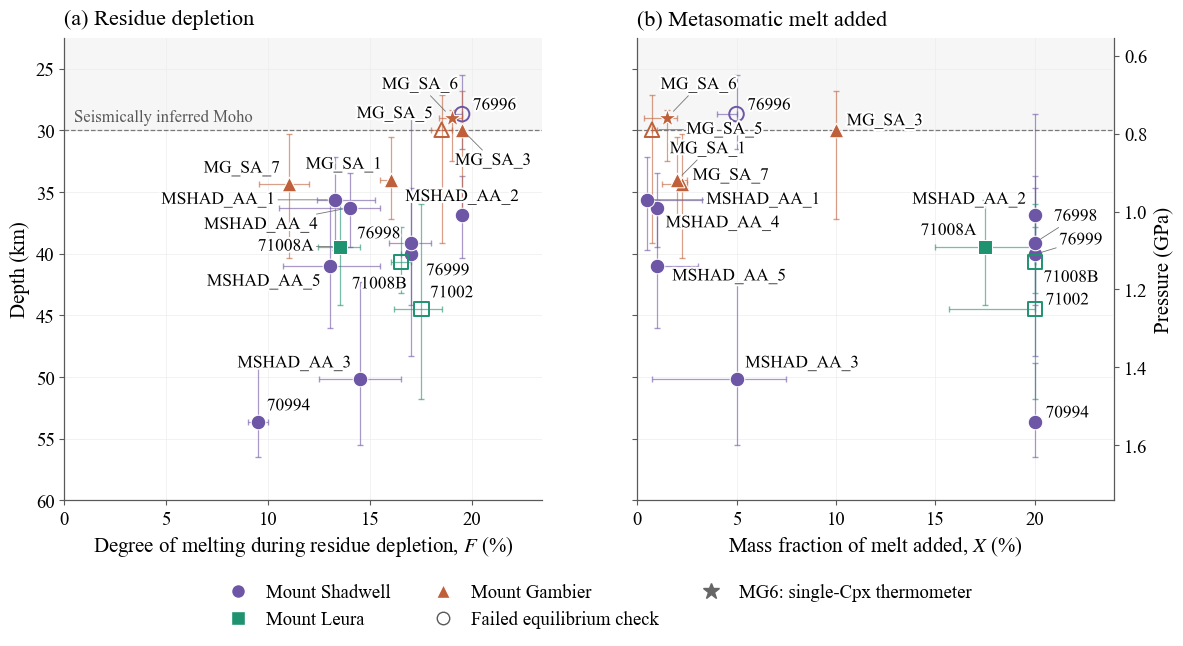

In [18]:
# Figure 7.9
PT_T98 = pd.DataFrame([
    ('MSHAD_AA_3',964,1.43,1.18,1.60,50,''), ('MSHAD_AA_5',866,1.14,0.97,1.30,41,''),
    ('76999',858,1.11,0.94,1.24,40,''), ('71008A',850,1.09,0.97,1.24,39,''),
    ('76998',846,1.08,0.75,1.37,39,''), ('MSHAD_AA_2',823,1.01,0.91,1.12,37,''),
    ('MSHAD_AA_4',815,0.99,0.90,1.09,36,''), ('MSHAD_AA_1',808,0.97,0.86,1.10,36,''),
    ('76997',740,0.78,0.75,0.93,30,'disequilibrium'),
    ('70984',724,0.76,0.72,0.89,29,''),
    ('76996',712,0.75,0.65,0.84,28,'disequilibrium'),
    ('70994',999,1.54,1.39,1.63,54,''),
    ('71002',904,1.25,0.98,1.48,44,'disequilibrium'),
    ('71008B',864,1.13,1.04,1.21,41,'disequilibrium'),
    ('MG_SA_2',824,1.01,0.83,1.21,37,''), ('MG_SA_7',797,0.93,0.80,1.12,35,''),
    ('MG_SA_1',792,0.92,0.81,1.02,34,''), ('MG_SA_5',748,0.79,0.70,1.08,30,'disequilibrium'),
    ('MG_SA_3',744,0.79,0.69,1.02,30,''), ('MG_SA_6',725,0.76,0.74,0.87,29,'')],
    columns=['xenolith', 'T', 'P', 'P16', 'P84', 'depth', 'flag']
).set_index('xenolith')

MOHO_P = 0.79
p2z = np.polyfit(PT_T98['P'], PT_T98['depth'], 1)
def p_to_z(p):
    return np.polyval(p2z, p)
def z_to_p(z):
    return (np.asarray(z) - p2z[1]) / p2z[0]
MOHO_Z = float(p_to_z(MOHO_P))

bf = pd.DataFrame({
    'xenolith': inv['xenolith'].astype(str).str.strip().str.upper().to_numpy(),
    'F': 100 * pd.to_numeric(inv['F_res'], errors='coerce').to_numpy(),
    'X': 100 * pd.to_numeric(inv['X'], errors='coerce').to_numpy(),
    'D': pd.to_numeric(inv['D_min'], errors='coerce').to_numpy(),
})
bf = bf.loc[(bf['D'] <= D_BROAD) & bf[['F', 'X']].notna().all(axis=1)]
stats = pd.DataFrame.from_dict({
    x: {f'{variable}{q}': float(np.percentile(g[variable], q))
        for variable in ('F', 'X') for q in (16, 50, 84)}
    for x, g in bf.groupby('xenolith')
}, orient='index').reindex(columns=[f'{variable}{q}' for variable in ('F', 'X') for q in (16, 50, 84)])
loc = (inv.assign(xenolith=inv['xenolith'].astype(str).str.strip().str.upper())
         .groupby('xenolith')['Location'].first())

FAILED_EQ = PT_T98.index[
    PT_T98['flag'].str.contains('disequilibrium', case=False, na=False)
]
dp = PT_T98.join(loc.rename('Location')).join(stats)
dp['depth_est'], dp['depth16'], dp['depth84'] = p_to_z(dp['P']), p_to_z(dp['P16']), p_to_z(dp['P84'])

BIG_RC = {**THESIS_RC, 'font.size': 14, 'axes.labelsize': 15,
          'xtick.labelsize': 13.5, 'ytick.labelsize': 13.5, 'legend.fontsize': 13.5}
TITLE_FS, LABEL_FS, MOHO_FS = 16, 12.5, 12
PANEL_TITLES = ('(a) Residue depletion', '(b) Metasomatic melt added')
MS, MS_STAR = 110, 180


def place_labels(ax, pts, bars, avoid=(), fontsize=LABEL_FS):
    fig = ax.figure
    fig.canvas.draw()
    rend = fig.canvas.get_renderer()
    k = fig.dpi / 72
    P = ax.transData.transform([(x, y) for _, x, y, _ in pts])
    r = np.array([0.5 * d * k for *_, d in pts])
    wh = []
    for name, *_ in pts:
        t = ax.text(0, 0, name, fontsize=fontsize)
        e = t.get_window_extent(rend)
        t.remove()
        wh.append((e.width + 3 * k, e.height + 1.5 * k))
    as_rects = lambda v: np.asarray(v, float).reshape(-1, 4)
    marks = as_rects([(px - ri, py - ri, px + ri, py + ri) for (px, py), ri in zip(P, r)])
    segs = []
    for (xa, ya), (xb, yb) in bars:
        (pa, qa), (pb, qb) = ax.transData.transform([(xa, ya), (xb, yb)])
        segs.append((min(pa, pb) - k, min(qa, qb) - k, max(pa, pb) + k, max(qa, qb) + k))
    segs = as_rects(segs)
    other = as_rects([art.get_window_extent(rend).extents for art in avoid])
    frame = as_rects(ax.get_window_extent(rend).extents)
    LEADER = 8 * k

    def area(b, R):
        if not len(R):
            return 0.0
        w = np.minimum(b[2], R[:, 2]) - np.maximum(b[0], R[:, 0])
        h = np.minimum(b[3], R[:, 3]) - np.maximum(b[1], R[:, 1])
        return float((np.clip(w, 0, None) * np.clip(h, 0, None)).sum())

    def gap_to(b, Q):
        dx = np.maximum.reduce([b[0] - Q[:, 0], np.zeros(len(Q)), Q[:, 0] - b[2]])
        dy = np.maximum.reduce([b[1] - Q[:, 1], np.zeros(len(Q)), Q[:, 1] - b[3]])
        return np.hypot(dx, dy)

    def hits(p, q, R):
        n, d = 0, q - p
        for x0, y0, x1, y1 in R:
            t0, t1 = 0.0, 1.0
            for dp, lo, hi in ((d[0], x0 - p[0], x1 - p[0]), (d[1], y0 - p[1], y1 - p[1])):
                if abs(dp) < 1e-9:
                    t0 = t0 if lo <= 0 <= hi else 2.0
                else:
                    u0, u1 = sorted((lo / dp, hi / dp))
                    t0, t1 = max(t0, u0), min(t1, u1)
            n += t0 < t1
        return n

    def crosses(p, q, s, t):
        c = lambda a, b, e: (b[0] - a[0]) * (e[1] - a[1]) - (b[1] - a[1]) * (e[0] - a[0])
        return c(p, q, s) * c(p, q, t) < 0 and c(s, t, p) * c(s, t, q) < 0

    def candidates(i):
        w, h = wh[i]
        out = []
        for g in np.array([1.5, 5, 12, 18, 26, 36]) * k:
            for a in np.deg2rad(np.arange(0, 360, 22.5)):
                u = np.array([np.cos(a), np.sin(a)])
                c = P[i] + (r[i] + g) * u + 0.5 * np.array([w, h]) * np.clip(1.42 * u, -1, 1)
                out.append(c)
        for side in (-1, 1):
            for dy in np.array([-36, -27, -18, -12, 12, 18, 27, 36]) * k:
                out.append(P[i] + (side * (r[i] + 4 * k + w / 2), dy))
        return [np.array([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2]) for cx, cy in out]

    def leader(i, b):
        c = np.array([(b[0] + b[2]) / 2, (b[1] + b[3]) / 2])
        d = c - P[i]
        t = max(min((b[m] - P[i][m]) / d[m], (b[m + 2] - P[i][m]) / d[m]) for m in (0, 1) if abs(d[m]) > 1e-9)
        return P[i] + r[i] * d / max(np.hypot(*d), 1e-9), P[i] + np.clip(t, 0, 1) * d

    def cost(i, b, placed):
        others = [j for j in placed if j != i]
        ob = as_rects([placed[j][0] for j in others])
        rest = np.delete(np.arange(len(P)), i)
        g = gap_to(b, P[[i]])[0] - r[i]
        near = gap_to(b, P[rest]) - r[rest]
        cx, cy = (b[0] + b[2]) / 2 - P[i][0], (b[1] + b[3]) / 2 - P[i][1]
        c = (60 * area(b, ob) + 25 * area(b, marks[rest]) + 30 * area(b, other) + 1 * area(b, segs)
             + 80 * ((b[2] - b[0]) * (b[3] - b[1]) - area(b, frame))
             + 4 * g / k + 3 * (1 - np.cos(np.arctan2(cy, cx) - np.pi / 4)))
        if g <= LEADER:
            c += 40 * np.clip(g + 4 * k - near, 0, None).sum() / k
        else:
            p, q = leader(i, b)
            c += (15 + 40 * np.clip(6 * k - near, 0, None).sum() / k
                  + 3000 * hits(p, q, ob) + 1500 * hits(p, q, marks[rest]))
            c += 3000 * sum(placed[j][1] > LEADER and crosses(p, q, *leader(j, placed[j][0])) for j in others)
        for j in others:
            if placed[j][1] > LEADER:
                c += 3000 * hits(*leader(j, placed[j][0]), as_rects(b))
        return c, g

    dist = np.hypot(*(P[:, None, :] - P[None, :, :]).transpose(2, 0, 1))
    order = np.argsort(-(dist < 60 * k).sum(1), kind='stable')
    cands = {i: candidates(i) for i in order}
    placed = {}
    for _ in range(6):
        for i in order:
            scored = [(cost(i, b, placed), n) for n, b in enumerate(cands[i])]
            (_, g), n = min(scored, key=lambda t: t[0][0])
            placed[i] = (cands[i][n], g)
    for i, (name, x, y, d) in enumerate(pts):
        b, g = placed[i]
        offset = (np.array([(b[0] + b[2]) / 2, (b[1] + b[3]) / 2]) - P[i]) / k
        ax.annotate(name, (x, y), xytext=offset, textcoords='offset points', ha='center', va='center',
                    fontsize=fontsize, zorder=6, annotation_clip=False,
                    arrowprops=dict(arrowstyle='-', lw=0.6, color='0.45', shrinkA=0, shrinkB=0.5 * d)
                    if g > LEADER else None,
                    path_effects=[pe.withStroke(linewidth=3, foreground='white')])


plotted = dp.dropna(subset=['F16', 'F50', 'F84', 'X16', 'X50', 'X84', 'P', 'P16', 'P84', 'Location',
                            'depth_est', 'depth16', 'depth84']).copy()
fmax = max(10, float(plotted['F84'].max()) * 1.2)
xmax = max(1, float(plotted['X84'].max()) * 1.2)
zmin = min(25, float(plotted['depth16'].min()) - 3, MOHO_Z - 3)
zmax = max(60, float(plotted['depth84'].max()) + 3, MOHO_Z + 3)
failed_plotted = plotted.index[plotted.index.isin(FAILED_EQ)].tolist()

print(f'No accepted fit (D <= {D_BROAD:g}): {", ".join(dp.index[dp["F50"].isna()])}')
for variable, description in [('F50', 'depletion F'), ('X50', 'melt addition X')]:
    rho = plotted[['T', variable]].corr(method='spearman').loc['T', variable]
    print(f'Spearman rho(T, {description}) = {rho:.2f} (n={len(plotted)})')
    for site in SITES:
        ss = plotted.loc[plotted['Location'] == site]
        rr = ss[['T', variable]].corr(method='spearman').loc['T', variable] if len(ss) >= 3 else np.nan
        print(f'  {mount(site)}: rho={rr:.2f}, n={len(ss)}')

with plt.rc_context(BIG_RC):
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 6.6), sharey=True)
    fig.subplots_adjust(left=0.075, right=0.915, top=0.92, bottom=0.22, wspace=0.2)
    to_label = []
    for j, (ax, variable, xlabel, lim) in enumerate(zip(
            axes, ('F', 'X'), (F_LABEL, X_LABEL), (fmax, xmax))):
        ax.axhspan(0, MOHO_Z, color=GRID_GREY, alpha=0.45, zorder=0)
        ax.axhline(MOHO_Z, color='0.48', ls='--', lw=0.9, zorder=1)
        avoid = []
        if j == 0:
            avoid.append(ax.annotate('Seismically inferred Moho', (0.02, MOHO_Z),
                                     xycoords=ax.get_yaxis_transform(), xytext=(0, 6),
                                     textcoords='offset points', ha='left', fontsize=MOHO_FS, color='0.35'))
        ax.set_title(PANEL_TITLES[j], loc='left', fontsize=TITLE_FS, pad=10)
        pts, bars = [], []
        for xenolith, r in plotted.iterrows():
            col = SITE_COLOURS[r['Location']]
            diseq = xenolith in FAILED_EQ
            single_cpx = xenolith == 'MG_SA_6'
            xval, z = float(r[f'{variable}50']), float(r['depth_est'])
            x16, x84 = float(r[f'{variable}16']), float(r[f'{variable}84'])
            ax.errorbar(xval, z,
                xerr=[[max(0., xval - x16)], [max(0., x84 - xval)]],
                yerr=[[max(0., z - r['depth16'])], [max(0., r['depth84'] - z)]],
                fmt='none', ecolor=col, elinewidth=0.9, capsize=2,
                alpha=0.6, zorder=2)
            size = MS_STAR if single_cpx else MS
            ax.scatter(xval, z,
                marker='*' if single_cpx else SITE_MARKERS[r['Location']],
                s=size, linewidth=1.4 if diseq else 0.75,
                facecolor='none' if diseq else col,
                edgecolor=col if diseq else 'white', zorder=4)
            pts.append((xenolith, xval, z, np.sqrt(size)))
            bars += [((x16, z), (x84, z)), ((xval, r['depth16']), (xval, r['depth84']))]
        ax.set_xlim(0, lim)
        ax.set_ylim(zmax, zmin)
        ax.set_xlabel(xlabel)
        ax.grid(color=GRID_GREY, lw=0.5)
        ax.set_axisbelow(True)
        to_label.append((ax, pts, bars, avoid))
    axes[0].set_ylabel('Depth (km)')
    axes[1].secondary_yaxis('right', functions=(z_to_p, p_to_z)).set_ylabel('Pressure (GPa)')

    handles = [Line2D([0], [0], ls='', marker=SITE_MARKERS[site], ms=10,
                      markerfacecolor=SITE_COLOURS[site], markeredgecolor='white',
                      color=SITE_COLOURS[site], label=mount(site)) for site in SITES]
    if failed_plotted:
        handles.append(Line2D([0], [0], ls='', marker='o', ms=9,
                              markerfacecolor='none', markeredgecolor='0.35',
                              label='Failed equilibrium check'))
    if 'MG_SA_6' in plotted.index:
        handles.append(Line2D([0], [0], ls='', marker='*', ms=12,
                              color='0.4', label='MG6: single-Cpx thermometer'))
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.0),
               ncol=3, handletextpad=0.5, columnspacing=1.8, frameon=False)
    for ax, pts, bars, avoid in to_label:
        place_labels(ax, pts, bars, avoid)
    save(fig, 'ch7_NVP_depth_vs_depletion_and_melt_added_T98')